<a href="https://colab.research.google.com/github/Research-methods-group5/Hackathon_groupO/blob/main/Covid_vaccine_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COVID-19 Vaccination Prediction and Municipal Cost Optimisation

**Objective:** Help the mayor predict individual vaccination acceptance and minimise estimated municipal expenditure.


In [56]:
#IMPORT THE LIBRARIES


# Data manipulation
import numpy as np
import pandas as pd

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

# Machine learning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Classification models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Explainability
from sklearn.inspection import (
    permutation_importance,
    PartialDependenceDisplay
)

# Probability calibration
from sklearn.calibration import (
    CalibratedClassifierCV,
    CalibrationDisplay
)

# General settings
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(
    style="whitegrid",
    palette="colorblind"
)

plt.rcParams.update({
    "figure.figsize": (8, 6),
    "figure.dpi": 90,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "legend.fontsize": 10
})

print("All libraries imported successfully!")
print("Mayor's Vaccination Optimisation Project is ready.")


All libraries imported successfully!
Mayor's Vaccination Optimisation Project is ready.


In [57]:

train = pd.read_csv("dataset_C_training.csv")
test = pd.read_csv("dataset_C_testing.csv")

print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

print("\nTraining dataset:")
display(train.head())

print("\nTesting dataset:")
display(test.head())


Training dataset shape: (4756, 31)
Testing dataset shape: (4749, 30)

Training dataset:


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0



Testing dataset:


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,employment_status,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",0.0,0.0,0,4,2,2.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,NaN,"MSA, Not Principle City",0.0,0.0,0,2,3,2.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",1.0,0.0,0,3,2,2.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Employed,Non-MSA,1.0,0.0,0,4,4,1.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Employed,Non-MSA,0.0,0.0,0,3,2,1.0,wholesale,0


In [58]:

print("Training dataset information:")
train.info()

print("\nTesting dataset information:")
test.info()

print("\nDuplicate records:")
print("Training:", train.duplicated().sum())
print("Testing:", test.duplicated().sum())

print("\nMissing values in training:")
missing_train = train.isnull().sum()
display(missing_train[missing_train > 0].sort_values(ascending=False).to_frame("Missing Count"))

print("\nMissing values in testing:")
missing_test = test.isnull().sum()
display(missing_test[missing_test > 0].sort_values(ascending=False).to_frame("Missing Count"))

print("\nVaccination target distribution:")
target_counts = train["covid_vaccine"].value_counts().sort_index()
target_percentages = train["covid_vaccine"].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

display(target_summary)

print("\nFeature consistency:")
train_features = set(train.columns) - {"covid_vaccine"}
test_features = set(test.columns)

print("Same predictor columns:", train_features == test_features)
print("Training respondent IDs unique:", train["respondent_id"].is_unique)
print("Testing respondent IDs unique:", test["respondent_id"].is_unique)


Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   covid_concern                  4744 non-null   float64
 2   covid_knowledge                4729 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4754 non-null   float64
 6   behavioral_wash_hands          4747 non-null   float64
 7   behavioral_large_gatherings    4746 non-null   float64
 8   behavioral_outside_home        4742 non-null   float64
 9   behavioral_touch_face          4735 non-null   float64
 10  child_under_6_months           4621 non-null   float64
 11  health_worker                  4624 non-null   float64
 12  health_insurance  

,Missing Count
employment_sector,2330
health_insurance,1908
income_poverty,748
rent_or_own,329
employment_status,238
marital_status,231
education,228
child_under_6_months,135
health_worker,132
opinion_covid_sick_from_vacc,90



Missing values in testing:


,Missing Count
employment_sector,2405
health_insurance,1982
income_poverty,797
rent_or_own,379
employment_status,277
marital_status,269
education,269
child_under_6_months,155
health_worker,149
opinion_covid_sick_from_vacc,107



Vaccination target distribution:


,Count,Percentage
covid_vaccine,,
0,3202,67.33
1,1554,32.67



Feature consistency:
Same predictor columns: True
Training respondent IDs unique: True
Testing respondent IDs unique: True


,Training Missing (%),Testing Missing (%)
employment_sector,48.99,50.64
health_insurance,40.12,41.74
income_poverty,15.73,16.78
rent_or_own,6.92,7.98
employment_status,5.00,5.83
marital_status,4.86,5.66
education,4.79,5.66
child_under_6_months,2.84,3.26
health_worker,2.78,3.14
opinion_covid_sick_from_vacc,1.89,2.25


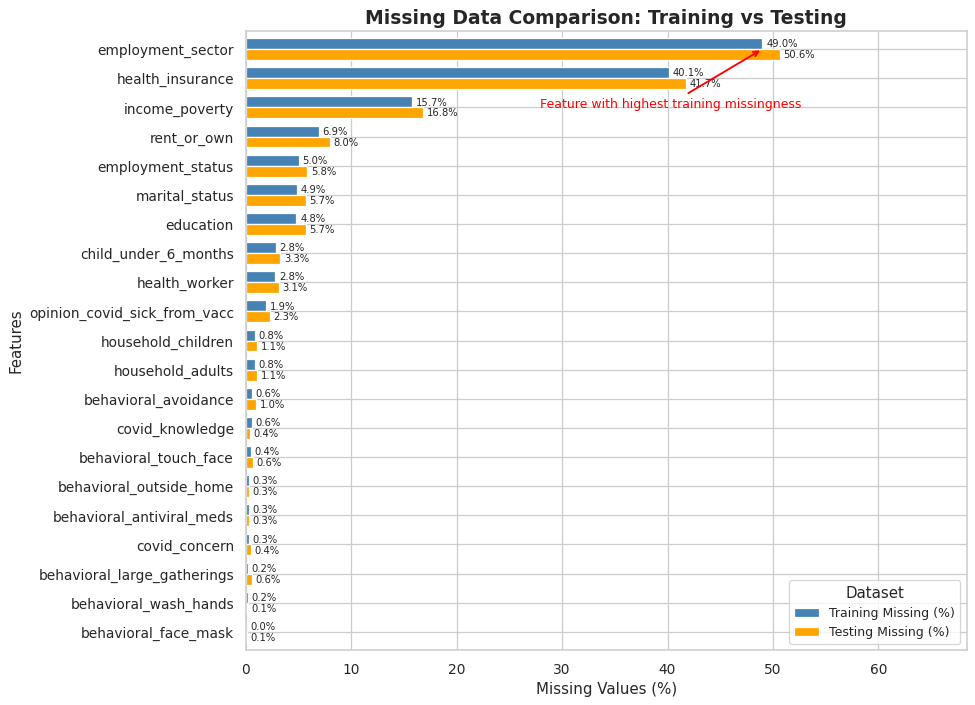

In [59]:

missing_summary = pd.DataFrame({
    "Training Missing (%)": train.isnull().mean() * 100,
    "Testing Missing (%)": test.isnull().mean() * 100
}).fillna(0)

missing_summary = missing_summary[
    (missing_summary["Training Missing (%)"] > 0) |
    (missing_summary["Testing Missing (%)"] > 0)
].sort_values("Training Missing (%)", ascending=False)

display(missing_summary.round(2))

fig, ax = plt.subplots(figsize=(11, 8))

missing_summary.plot(
    kind="barh",
    ax=ax,
    color=["steelblue", "orange"],
    width=0.75
)

ax.set_title("Missing Data Comparison: Training vs Testing")
ax.set_xlabel("Missing Values (%)")
ax.set_ylabel("Features")
ax.legend(title="Dataset")

ax.invert_yaxis()

max_missing = missing_summary.max().max()
ax.set_xlim(0, max_missing * 1.35)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=8)

if not missing_summary.empty:
    top_feature = missing_summary.index[0]
    top_value = missing_summary.iloc[0, 0]

    ax.annotate(
        "Feature with highest training missingness",
        xy=(top_value, 0),
        xytext=(max_missing * 0.55, 2),
        arrowprops=dict(arrowstyle="->", color="red", lw=1.5),
        color="red",
        fontsize=10
    )

plt.tight_layout()
plt.show()


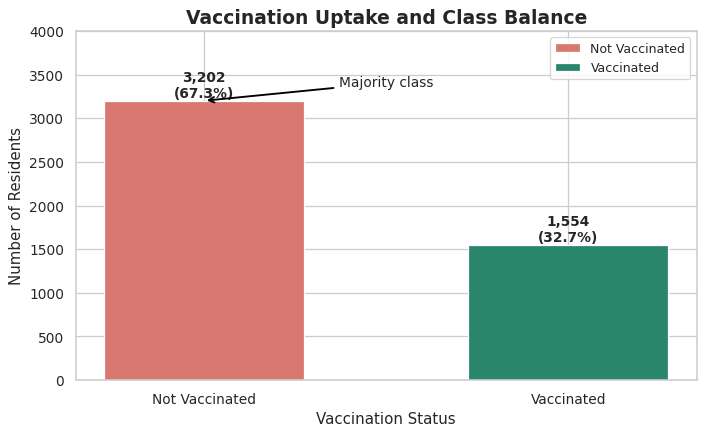

Class distribution:


,Count,Percentage
covid_vaccine,,
0,3202,67.33
1,1554,32.67


In [60]:

target_counts = train["covid_vaccine"].value_counts().sort_index()
target_pct = train["covid_vaccine"].value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Not Vaccinated", "Vaccinated"],
    target_counts.values,
    color=["#D97870", "#29866B"],
    width=0.55,
    label="Number of residents"
)

for i, bar in enumerate(bars):
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height + 35,
        f"{int(height):,}\n({target_pct.iloc[i]:.1f}%)",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

majority = target_counts.idxmax()
majority_label = "Vaccinated" if majority == 1 else "Not Vaccinated"

ax.annotate(
    "Majority class",
    xy=(majority, target_counts.loc[majority]),
    xytext=(0.5, target_counts.max() * 1.05),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
    ha="center",
    fontsize=11
)

ax.set_title("Vaccination Uptake and Class Balance")
ax.set_xlabel("Vaccination Status")
ax.set_ylabel("Number of Residents")
ax.set_ylim(0, target_counts.max() * 1.25)
from matplotlib.patches import Patch

legend_items = [
    Patch(facecolor="#D97870", label="Not Vaccinated"),
    Patch(facecolor="#29866B", label="Vaccinated")
]

ax.legend(handles=legend_items, loc="upper right")

plt.tight_layout()
plt.savefig("vaccination_class_balance.png", dpi=300, bbox_inches="tight")
plt.show()

print("Class distribution:")
display(pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_pct.round(2)
}))


,Age Group,Residents,Vaccinated,Vaccination Rate
0,18 - 34 Years,947,244,25.77
1,35 - 44 Years,661,195,29.50
2,45 - 54 Years,948,296,31.22
3,55 - 64 Years,992,353,35.58
4,65+ Years,1208,466,38.58


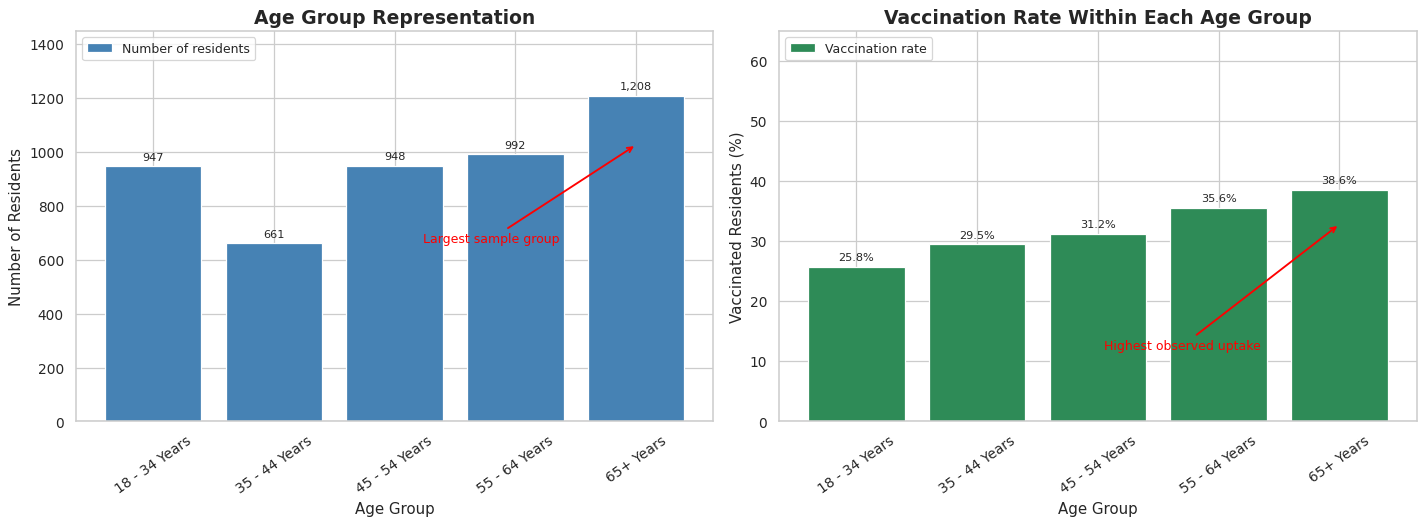

In [61]:

age_summary = (
    train.groupby("age_group", dropna=False)["covid_vaccine"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

age_summary.columns = [
    "Age Group", "Residents", "Vaccinated", "Vaccination Rate"
]

age_summary["Age Group"] = age_summary["Age Group"].fillna("Missing")
age_summary["Vaccination Rate"] *= 100

display(age_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Number of residents in each age group
bars1 = axes[0].bar(
    age_summary["Age Group"],
    age_summary["Residents"],
    color="steelblue",
    label="Number of residents"
)

axes[0].set_title("Age Group Representation")
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("Number of Residents")
axes[0].set_ylim(0, age_summary["Residents"].max() * 1.2)
axes[0].tick_params(axis="x", rotation=35)
axes[0].legend(loc="upper left")

for bar in bars1:
    axes[0].annotate(
        f"{int(bar.get_height()):,}",
        xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

largest = age_summary["Residents"].idxmax()

axes[0].annotate(
    "Largest sample group",
    xy=(largest, age_summary.loc[largest, "Residents"] * 0.85),
    xytext=(2.8, age_summary["Residents"].max() * 0.55),
    arrowprops=dict(
        arrowstyle="->",
        color="red",
        lw=1.5
    ),
    fontsize=10,
    color="red",
    ha="center"
)

# Vaccination rate within each age group
bars2 = axes[1].bar(
    age_summary["Age Group"],
    age_summary["Vaccination Rate"],
    color="seagreen",
    label="Vaccination rate"
)

axes[1].set_title("Vaccination Rate Within Each Age Group")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Vaccinated Residents (%)")
axes[1].set_ylim(0, 65)
axes[1].tick_params(axis="x", rotation=35)
axes[1].legend(loc="upper left")

for bar in bars2:
    axes[1].annotate(
        f"{bar.get_height():.1f}%",
        xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

highest = age_summary["Vaccination Rate"].idxmax()

axes[1].annotate(
    "Highest observed uptake",
    xy=(highest, age_summary.loc[highest, "Vaccination Rate"] * 0.85),
    xytext=(2.7, 12),
    arrowprops=dict(
        arrowstyle="->",
        color="red",
        lw=1.5
    ),
    fontsize=10,
    color="red",
    ha="center"
)

plt.tight_layout()
plt.savefig("age_group_sampling_bias.png", dpi=300, bbox_inches="tight")
plt.show()


,Feature,P-value,Cramers V,Minimum Expected Count
0,doctor_recc_covid,0.0000,0.4298,353.5383
1,opinion_covid_risk,0.0000,0.3802,31.3675
2,opinion_covid_vacc_effective,0.0000,0.3323,30.0606
3,health_insurance,0.0000,0.3002,99.3305
4,employment_sector,0.0000,0.2330,0.6535
5,health_worker,0.0000,0.1963,43.1304
6,covid_knowledge,0.0000,0.1696,8.8221
7,covid_concern,0.0000,0.1352,3.9209
8,number_chronic_med_conditions,0.0000,0.1312,0.3267
9,education,0.0000,0.1149,74.4979


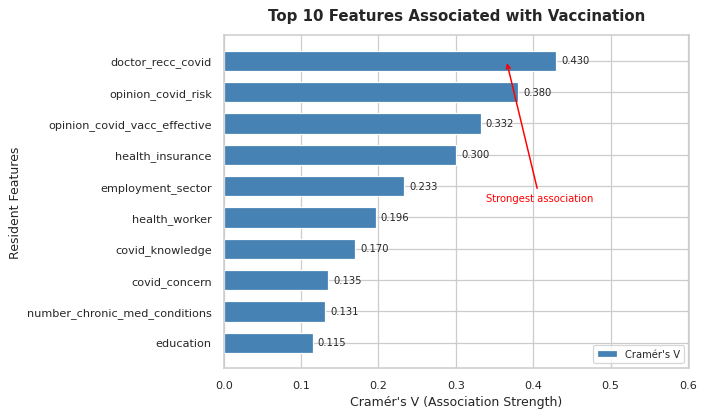


Health insurance association:


,Feature,P-value,Cramers V,Minimum Expected Count
3,health_insurance,0.0,0.3002,99.3305



Features with sparse expected counts:


,Feature,Minimum Expected Count
4,employment_sector,0.653490
7,covid_concern,3.920942
8,number_chronic_med_conditions,0.326745
15,opinion_covid_sick_from_vacc,3.267452
16,behavioral_wash_hands,2.940706
22,behavioral_face_mask,0.653490
26,behavioral_outside_home,4.574432
27,behavioral_antiviral_meds,4.574432
28,behavioral_large_gatherings,3.267452


In [62]:

# Cell 7: Feature Association Analysis

from scipy.stats import chi2_contingency

results = []

features = [
    col for col in train.columns
    if col not in ["respondent_id", "covid_vaccine"]
]

for feature in features:
    data = train[[feature, "covid_vaccine"]].copy()
    data[feature] = data[feature].astype("string").fillna("Missing")

    table = pd.crosstab(data[feature], data["covid_vaccine"])

    if table.shape[0] < 2 or table.shape[1] < 2:
        continue

    chi2, p_value, dof, expected = chi2_contingency(table)
    n = table.to_numpy().sum()

    cramers_v = np.sqrt(
        chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1))
    )

    results.append({
        "Feature": feature,
        "P-value": p_value,
        "Cramers V": cramers_v,
        "Minimum Expected Count": expected.min()
    })

feature_results = pd.DataFrame(results).sort_values(
    "Cramers V", ascending=False
).reset_index(drop=True)

display(feature_results.round(4))

top_features = feature_results.head(10).sort_values("Cramers V")

fig, ax = plt.subplots(figsize=(8, 4.8))

bars = ax.barh(
    top_features["Feature"],
    top_features["Cramers V"],
    color="steelblue",
    height=0.65,
    label="Cramér's V"
)

ax.set_title(
    "Top 10 Features Associated with Vaccination",
    fontsize=12,
    fontweight="bold",
    pad=12
)
ax.set_xlabel("Cramér's V (Association Strength)", fontsize=10)
ax.set_ylabel("Resident Features", fontsize=10)
ax.tick_params(axis="both", labelsize=9)
ax.set_xlim(0, top_features["Cramers V"].max() * 1.4)
ax.legend(loc="lower right", fontsize=8)

for bar in bars:
    ax.annotate(
        f"{bar.get_width():.3f}",
        xy=(bar.get_width(), bar.get_y() + bar.get_height()/2),
        xytext=(4, 0),
        textcoords="offset points",
        va="center",
        fontsize=8
    )

strongest = top_features.iloc[-1]

ax.annotate(
    "Strongest association",
    xy=(strongest["Cramers V"] * 0.85, len(top_features)-1),
    xytext=(strongest["Cramers V"] * 0.95, len(top_features)-5.5),
    arrowprops=dict(
        arrowstyle="->",
        color="red",
        lw=1.2
    ),
    color="red",
    fontsize=8,
    ha="center"
)

plt.tight_layout()
plt.savefig("feature_association_ppt.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nHealth insurance association:")
display(
    feature_results[
        feature_results["Feature"] == "health_insurance"
    ].round(4)
)

print("\nFeatures with sparse expected counts:")
display(
    feature_results[
        feature_results["Minimum Expected Count"] < 5
    ][["Feature", "Minimum Expected Count"]]
)


Number of selected features: 28

Excluded features: ['respondent_id', 'health_insurance', 'covid_vaccine']


,Selected Features
0,covid_concern
1,covid_knowledge
2,behavioral_antiviral_meds
3,behavioral_avoidance
4,behavioral_face_mask
5,behavioral_wash_hands
6,behavioral_large_gatherings
7,behavioral_outside_home
8,behavioral_touch_face
9,child_under_6_months



Class balance comparison:


,Full training (%),Model training (%),Validation (%)
covid_vaccine,,,
Not Vaccinated,67.33,67.32,67.33
Vaccinated,32.67,32.68,32.67


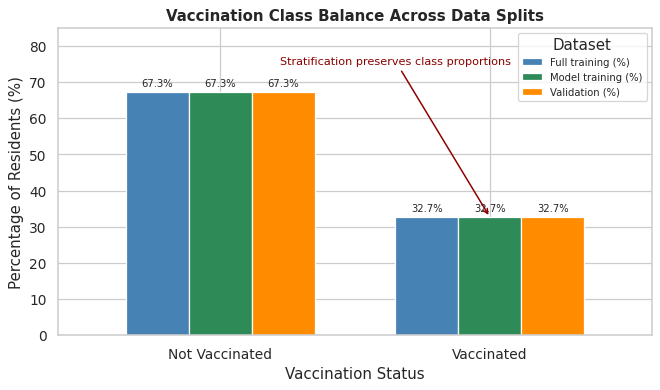


Training records: 3804
Validation records: 952
Competition testing records: 4749


In [63]:

# Cell 9: Feature Selection and Stratified Data Splitting

from sklearn.model_selection import train_test_split

target = "covid_vaccine"

excluded_features = [
    "respondent_id",
    "health_insurance",
    target
]

selected_features = [
    col for col in train.columns
    if col not in excluded_features
    and col in test.columns
]

X = train[selected_features].copy()
y = train[target].copy()
X_test = test[selected_features].copy()

print("Number of selected features:", len(selected_features))
print("\nExcluded features:", excluded_features)

display(pd.DataFrame({
    "Selected Features": selected_features
}))

assert y.notna().all(), "Missing target values found"
assert set(y.unique()) == {0, 1}, "Unexpected target labels"
assert X.columns.equals(X_test.columns), "Feature mismatch"

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

balance = pd.DataFrame({
    "Full training (%)": y.value_counts(normalize=True) * 100,
    "Model training (%)": y_train.value_counts(normalize=True) * 100,
    "Validation (%)": y_valid.value_counts(normalize=True) * 100
}).sort_index()

balance.index = balance.index.map({
    0: "Not Vaccinated",
    1: "Vaccinated"
})

print("\nClass balance comparison:")
display(balance.round(2))

fig, ax = plt.subplots(figsize=(7.5, 4.5))

balance.plot(
    kind="bar",
    ax=ax,
    color=["steelblue", "seagreen", "darkorange"],
    width=0.7
)

ax.set_title(
    "Vaccination Class Balance Across Data Splits",
    fontsize=12,
    fontweight="bold"
)
ax.set_xlabel("Vaccination Status")
ax.set_ylabel("Percentage of Residents (%)")
ax.set_xticklabels(balance.index, rotation=0)
ax.set_ylim(0, 85)
ax.legend(title="Dataset", fontsize=8)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=8
    )

ax.annotate(
    "Stratification preserves class proportions",
    xy=(1, balance.iloc[1]["Validation (%)"]),
    xytext=(0.65, 75),
    arrowprops=dict(
        arrowstyle="->",
        color="darkred",
        lw=1.2
    ),
    fontsize=9,
    color="darkred",
    ha="center"
)

plt.tight_layout()
plt.savefig(
    "class_balance_splits.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nTraining records:", len(X_train))
print("Validation records:", len(X_valid))
print("Competition testing records:", len(X_test))

pd.DataFrame({
    "Feature": selected_features
}).to_csv("selected_features.csv", index=False)


## Dataset Characteristics and Preprocessing

The dataset contains demographic, behavioural, health and vaccine-opinion features. The prediction target is COVID_VACCINE.

Missing numerical values are handled using median imputation, while missing categorical values use most-frequent imputation. Categorical features are encoded, and preprocessing is fitted using training data to prevent leakage.

A stratified training-validation split supports model evaluation while preserving vaccination class proportions.

In [64]:

# Cell 10: Data Preprocessing and Leakage Prevention

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Check feature types
categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

# Preprocessing for numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Check that the validation data has the same features
assert X_train.columns.equals(X_valid.columns)
assert X_train.columns.equals(X_test.columns)

# Check for overlapping respondent records
train_ids = set(train.loc[X_train.index, "respondent_id"])
valid_ids = set(train.loc[X_valid.index, "respondent_id"])
test_ids = set(test["respondent_id"])

assert train_ids.isdisjoint(valid_ids), "Training-validation ID overlap"
assert train_ids.isdisjoint(test_ids), "Training-testing ID overlap"
assert valid_ids.isdisjoint(test_ids), "Validation-testing ID overlap"

print("\nRespondent ID overlap checks passed.")
print("Training and validation features match.")
print("Preprocessing pipeline created successfully.")

# Check missing values before preprocessing
missing_summary = pd.DataFrame({
    "Training Missing (%)": X_train.isna().mean() * 100,
    "Validation Missing (%)": X_valid.isna().mean() * 100,
    "Testing Missing (%)": X_test.isna().mean() * 100
}).sort_values("Training Missing (%)", ascending=False)

display(missing_summary.round(2))

print("\nPreprocessing is ready for model pipelines.")


Categorical features: ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']
Numerical features: ['covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'number_chronic_med_conditions']

Respondent ID overlap checks passed.
Training and validation features match.
Preprocessing pipeline created successfully.


,Training Missing (%),Validation Missing (%),Testing Missing (%)
employment_sector,49.19,48.21,50.64
income_poverty,15.88,15.13,16.78
rent_or_own,7.10,6.20,7.98
employment_status,5.07,4.73,5.83
marital_status,4.97,4.41,5.66
education,4.89,4.41,5.66
child_under_6_months,2.81,2.94,3.26
health_worker,2.71,3.05,3.14
opinion_covid_sick_from_vacc,1.89,1.89,2.25
household_adults,0.79,0.95,1.05



Preprocessing is ready for model pipelines.


/tmp/ipykernel_583/2770471946.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(


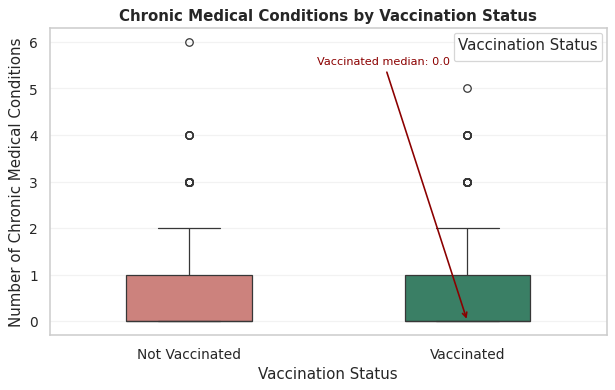

Chronic medical conditions summary:


,count,mean,median,std,min,max
Vaccination Status,,,,,,
Not Vaccinated,3202,0.33,0.0,0.63,0,6
Vaccinated,1554,0.49,0.0,0.73,0,5


In [65]:

# Cell 11: Chronic Conditions and Vaccination Status

target_col = "covid_vaccine"
feature_col = "number_chronic_med_conditions"

eda_data = train[[feature_col, target_col]].copy()
eda_data = eda_data.dropna()

eda_data["Vaccination Status"] = eda_data[target_col].map({
    0: "Not Vaccinated",
    1: "Vaccinated"
})

fig, ax = plt.subplots(figsize=(7, 4.5))

sns.boxplot(
    data=eda_data,
    x="Vaccination Status",
    y=feature_col,
    hue="Vaccination Status",
    palette={
        "Not Vaccinated": "#d97770",
        "Vaccinated": "#2e8b68"
    },
    dodge=False,
    width=0.45,
    ax=ax
)

ax.set_title(
    "Chronic Medical Conditions by Vaccination Status",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("Vaccination Status")
ax.set_ylabel("Number of Chronic Medical Conditions")

# Highlight the median of the vaccinated group
vaccinated_median = eda_data.loc[
    eda_data[target_col] == 1, feature_col
].median()

ax.annotate(
    f"Vaccinated median: {vaccinated_median:.1f}",
    xy=(1, vaccinated_median),
    xytext=(0.48, 0.88),
    textcoords="axes fraction",
    arrowprops=dict(
        arrowstyle="->",
        color="darkred",
        lw=1.3
    ),
    fontsize=9,
    color="darkred"
)

ax.legend(
    title="Vaccination Status",
    loc="upper right",
    fontsize=8
)

ax.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    "chronic_conditions_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Summary statistics
summary = eda_data.groupby(
    "Vaccination Status"
)[feature_col].agg([
    "count", "mean", "median", "std", "min", "max"
])

print("Chronic medical conditions summary:")
display(summary.round(2))


## Model Training, Evaluation and Explainability

Five models are evaluated: Logistic Regression, Random Forest, Extra Trees, Gradient Boosting and HistGradientBoosting.

ROC-AUC measures discrimination, while the Brier score evaluates probability prediction quality. Feature importance is used to identify characteristics associated with vaccination acceptance.

Gradient Boosting achieved the highest validation ROC-AUC of 0.8336. HistGradientBoosting was subsequently selected for the lowest estimated expenditure under the final scenario assumptions.

Logistic Regression completed
Random Forest completed
Extra Trees completed
Gradient Boosting completed
HistGradientBoosting completed

Model Performance Comparison


,Model,Accuracy,Precision,Recall,F1 Score,Balanced Accuracy,ROC-AUC,PR-AUC,Brier Score,Log Loss
0,Gradient Boosting,0.7994,0.7479,0.5820,0.6546,0.7434,0.8336,0.7170,0.1479,0.4605
1,Logistic Regression,0.8004,0.7469,0.5884,0.6583,0.7459,0.8271,0.7179,0.1493,0.4706
2,HistGradientBoosting,0.7962,0.7312,0.5949,0.6560,0.7444,0.8275,0.7129,0.1501,0.4666
3,Random Forest,0.7868,0.7547,0.5145,0.6119,0.7167,0.8253,0.7005,0.1549,0.4783
4,Extra Trees,0.7826,0.7500,0.5016,0.6012,0.7102,0.8268,0.6981,0.1553,0.4793


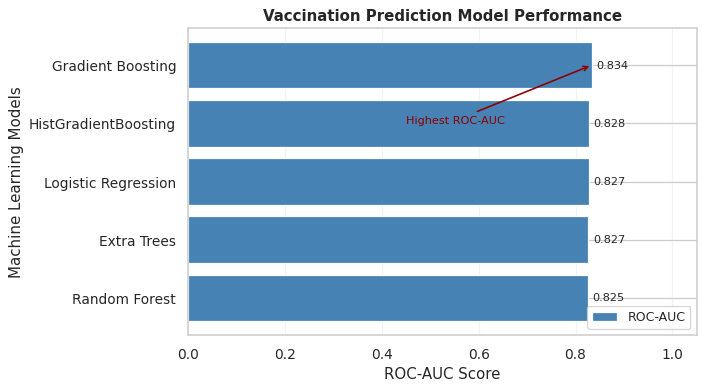


Trained models: 5
Saved probability arrays: 5
Cell 12 completed successfully.
Ready for Cell 13: Model Calibration.


In [67]:

# Cell 12: Model Training and Performance Comparison

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Five models for predicting vaccination acceptance

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.05,
        max_leaf_nodes=15,
        random_state=42
    )
}

# Store trained models and validation probabilities

trained_models = {}
model_probabilities = {}
model_results = []

for name, estimator in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", clone(estimator))
    ])

    pipeline.fit(X_train, y_train)

    probabilities = pipeline.predict_proba(X_valid)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    trained_models[name] = pipeline
    model_probabilities[name] = probabilities

    model_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Precision": precision_score(
            y_valid, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_valid, predictions, zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_valid, predictions
        ),
        "ROC-AUC": roc_auc_score(
            y_valid, probabilities
        ),
        "PR-AUC": average_precision_score(
            y_valid, probabilities
        ),
        "Brier Score": brier_score_loss(
            y_valid, probabilities
        ),
        "Log Loss": log_loss(
            y_valid, probabilities
        )
    })

    print(name, "completed")

# Compare model performance

model_comparison = pd.DataFrame(model_results)

model_comparison = model_comparison.sort_values(
    ["Brier Score", "ROC-AUC"],
    ascending=[True, False]
).reset_index(drop=True)

print("\nModel Performance Comparison")
display(model_comparison.round(4))

# Plot model performance

plot_data = model_comparison.sort_values(
    "ROC-AUC"
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.barh(
    plot_data["Model"],
    plot_data["ROC-AUC"],
    color="steelblue",
    label="ROC-AUC"
)

ax.set_title(
    "Vaccination Prediction Model Performance",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("ROC-AUC Score")
ax.set_ylabel("Machine Learning Models")
ax.set_xlim(0, 1.05)

for bar in bars:
    ax.text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.3f}",
        va="center",
        fontsize=9
    )

# Highlight the highest ROC-AUC model

best_position = int(
    np.argmax(plot_data["ROC-AUC"].values)
)

best_score = plot_data.loc[
    best_position, "ROC-AUC"
]

ax.annotate(
    "Highest ROC-AUC",
    xy=(best_score, best_position),
    xytext=(
        0.45,
        best_position - 1 if best_position > 0 else 1
    ),
    arrowprops=dict(
        arrowstyle="->",
        color="darkred",
        lw=1.3
    ),
    fontsize=9,
    color="darkred"
)

ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()

plt.savefig(
    "five_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save performance results

model_comparison.to_csv(
    "model_performance_comparison.csv",
    index=False
)

# Verify predictions are available for Cell 13

print("\nTrained models:", len(trained_models))
print("Saved probability arrays:", len(model_probabilities))

assert len(trained_models) == 5
assert len(model_probabilities) == 5

print("Cell 12 completed successfully.")
print("Ready for Cell 13: Model Calibration.")


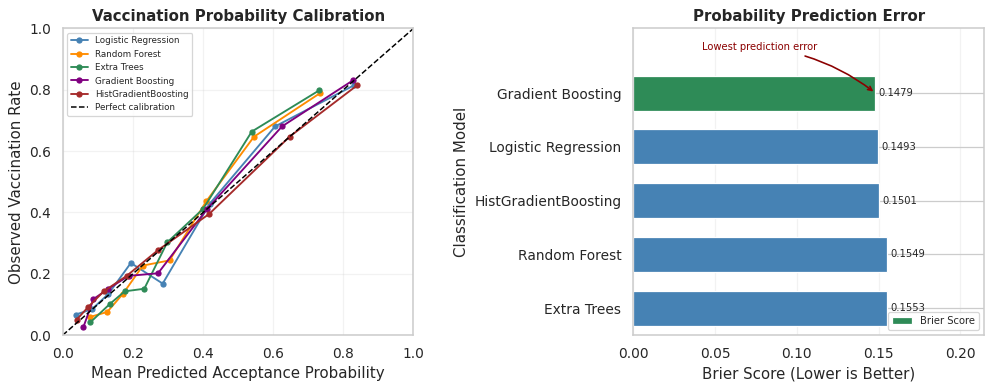

Model Calibration Results


,Model,Brier Score,Mean Predicted Uptake (%)
0,Gradient Boosting,0.1479,32.5223
1,Logistic Regression,0.1493,32.3180
2,HistGradientBoosting,0.1501,32.3496
3,Random Forest,0.1549,32.4749
4,Extra Trees,0.1553,32.3824



Actual validation vaccination rate: 32.67%
Best model by Brier Score: Gradient Boosting
Lowest Brier Score: 0.1479

Interpretation: Lower Brier Scores indicate more accurate probability predictions.
The best probability model is not necessarily the model that minimises town expenditure.


In [69]:

# Cell 13: Model Probability Calibration and Prediction Error

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check that validation predictions are available
if "model_probabilities" not in globals():
    raise NameError("Run Cell 12 first to create model_probabilities.")

if "y_valid" not in globals():
    raise NameError("Validation labels y_valid are not available.")

calibration_results = []

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))

colors = {
    "Logistic Regression": "steelblue",
    "Random Forest": "darkorange",
    "Extra Trees": "seagreen",
    "Gradient Boosting": "purple",
    "HistGradientBoosting": "brown"
}

# Compare predicted probabilities with observed vaccination rates
for name, probabilities in model_probabilities.items():

    probabilities = np.asarray(probabilities)

    observed, predicted = calibration_curve(
        y_valid,
        probabilities,
        n_bins=8,
        strategy="quantile"
    )

    axes[0].plot(
        predicted,
        observed,
        marker="o",
        markersize=4,
        linewidth=1.5,
        color=colors.get(name, "gray"),
        label=name
    )

    calibration_results.append({
        "Model": name,
        "Brier Score": brier_score_loss(
            y_valid, probabilities
        ),
        "Mean Predicted Uptake (%)": probabilities.mean() * 100
    })

# Left plot: Calibration curves
axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="black",
    linewidth=1.2,
    label="Perfect calibration"
)

axes[0].set_title(
    "Vaccination Probability Calibration",
    fontsize=12,
    fontweight="bold"
)
axes[0].set_xlabel("Mean Predicted Acceptance Probability")
axes[0].set_ylabel("Observed Vaccination Rate")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].legend(loc="upper left", fontsize=7)
axes[0].grid(alpha=0.25)

# Prepare probability error comparison
calibration_df = pd.DataFrame(
    calibration_results
).sort_values(
    "Brier Score"
).reset_index(drop=True)

best_model = calibration_df.loc[0, "Model"]
best_score = calibration_df.loc[0, "Brier Score"]

# Right plot: Brier Score
bar_colors = [
    "seagreen" if name == best_model else "steelblue"
    for name in calibration_df["Model"]
]

bars = axes[1].barh(
    calibration_df["Model"],
    calibration_df["Brier Score"],
    color=bar_colors,
    height=0.65,
    label="Brier Score"
)

axes[1].invert_yaxis()

axes[1].set_title(
    "Probability Prediction Error",
    fontsize=12,
    fontweight="bold"
)
axes[1].set_xlabel("Brier Score (Lower is Better)")
axes[1].set_ylabel("Classification Model")

max_score = calibration_df["Brier Score"].max()
axes[1].set_xlim(0, max_score * 1.38)
axes[1].set_ylim(len(calibration_df) - 0.5, -1.2)

# Display each score at the end of its bar
for bar in bars:
    axes[1].text(
        bar.get_width() + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.4f}",
        va="center",
        fontsize=8
    )

# Annotation positioned above the best-performing bar
axes[1].annotate(
    "Lowest prediction error",
    xy=(best_score, 0),
    xytext=(best_score * 0.52, -0.85),
    fontsize=8,
    color="darkred",
    ha="center",
    va="center",
    arrowprops=dict(
        arrowstyle="->",
        color="darkred",
        lw=1.3,
        connectionstyle="arc3,rad=-0.15"
    ),
    annotation_clip=False
)

axes[1].legend(loc="lower right", fontsize=8)
axes[1].grid(axis="x", alpha=0.25)
axes[1].set_axisbelow(True)

plt.tight_layout(pad=2)

plt.savefig(
    "vaccination_model_calibration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display numerical results
print("Model Calibration Results")
display(calibration_df.round(4))

actual_uptake = np.asarray(y_valid).mean() * 100

print(f"\nActual validation vaccination rate: {actual_uptake:.2f}%")
print(f"Best model by Brier Score: {best_model}")
print(f"Lowest Brier Score: {best_score:.4f}")

print(
    "\nInterpretation: Lower Brier Scores indicate more "
    "accurate probability predictions."
)
print(
    "The best probability model is not necessarily "
    "the model that minimises town expenditure."
)


COVID-19 Vaccination Financial Planning
Selected model: Gradient Boosting
Validation residents: 952
Vaccine cost: £1,500
Hospitalisation cost: £41,000

Actual vaccine acceptance: 311
Expected vaccine acceptance: 309.6
Expected uptake: 32.52%
Approximate 90% demand range: 290 to 329

Acceptance Threshold Comparison


,Threshold,Doses Planned,Expected Vaccinations,Expected Unused Doses,Expected Unmet Demand,Supply Cost (£),Precision,Recall
0,0.05,928,308.624,619.376,0.989,1392000,0.334,0.997
1,0.10,730,293.848,436.152,15.765,1095000,0.405,0.952
2,0.15,605,278.284,326.716,31.329,907500,0.461,0.897
3,0.20,513,262.254,250.746,47.359,769500,0.511,0.842
4,0.25,444,246.818,197.182,62.795,666000,0.556,0.794
5,0.30,378,228.728,149.272,80.885,567000,0.627,0.762
6,0.35,348,219.012,128.988,90.600,522000,0.647,0.723
7,0.40,305,202.956,102.044,106.656,457500,0.672,0.659
8,0.45,266,186.367,79.633,123.246,399000,0.718,0.614
9,0.50,242,175.069,66.931,134.544,363000,0.748,0.582


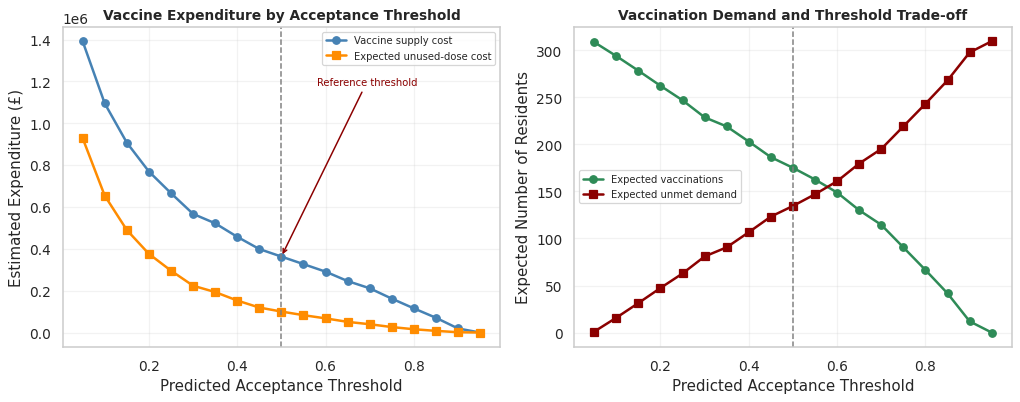


Competition test-set forecast
Test residents: 4,749
Expected acceptances: 1,590.0
Test acceptance probabilities saved to CSV.

Cell 14 completed.
Hospitalisation expenditure and the final cost-optimal threshold will be calculated in the next stage.


In [72]:
# Cell 14: Vaccine Expenditure and Acceptance Threshold Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# Hackathon costs
vaccine_cost = 1500
hospitalisation_cost = 41000

# Best model based on validation Brier Score
best_model_name = calibration_df.iloc[0]["Model"]

# Use validation predictions to evaluate thresholds
probabilities = np.asarray(
    model_probabilities[best_model_name],
    dtype=float
)

actual = np.asarray(y_valid).astype(int)

if len(probabilities) != len(actual):
    raise ValueError("Predictions and validation labels have different lengths.")

if not np.all(np.isfinite(probabilities)):
    raise ValueError("Predicted probabilities contain invalid values.")

if np.any((probabilities < 0) | (probabilities > 1)):
    raise ValueError("Predicted probabilities must be between 0 and 1.")

# Expected vaccine acceptance
n_residents = len(probabilities)
expected_acceptance = probabilities.sum()
actual_acceptance = actual.sum()

# Approximate uncertainty assuming independent acceptance decisions
acceptance_sd = np.sqrt(
    np.sum(probabilities * (1 - probabilities))
)

lower_acceptance = max(
    0,
    expected_acceptance - 1.645 * acceptance_sd
)

upper_acceptance = min(
    n_residents,
    expected_acceptance + 1.645 * acceptance_sd
)

print("COVID-19 Vaccination Financial Planning")
print(f"Selected model: {best_model_name}")
print(f"Validation residents: {n_residents:,}")
print(f"Vaccine cost: £{vaccine_cost:,.0f}")
print(f"Hospitalisation cost: £{hospitalisation_cost:,.0f}")

print(f"\nActual vaccine acceptance: {actual_acceptance:,}")
print(f"Expected vaccine acceptance: {expected_acceptance:,.1f}")
print(f"Expected uptake: {probabilities.mean()*100:.2f}%")

print(
    f"Approximate 90% demand range: "
    f"{lower_acceptance:,.0f} to {upper_acceptance:,.0f}"
)

# Evaluate thresholds from 0.05 to 0.95
thresholds = np.round(np.arange(0.05, 1.00, 0.05), 2)

threshold_results = []

for threshold in thresholds:

    # Residents predicted to accept vaccination
    selected = probabilities >= threshold

    doses_planned = int(selected.sum())

    # Expected uptake among selected residents
    expected_used = probabilities[selected].sum()

    # Expected unused vaccines
    expected_unused = doses_planned - expected_used

    # Expected acceptance among residents below threshold
    expected_unmet = probabilities[~selected].sum()

    # Validation classification results
    predicted = selected.astype(int)

    tp = int(np.sum((predicted == 1) & (actual == 1)))
    fp = int(np.sum((predicted == 1) & (actual == 0)))
    fn = int(np.sum((predicted == 0) & (actual == 1)))
    tn = int(np.sum((predicted == 0) & (actual == 0)))

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    # Financial estimates
    supply_cost = doses_planned * vaccine_cost

    expected_wastage_cost = (
        expected_unused * vaccine_cost
    )

    threshold_results.append({
        "Threshold": threshold,
        "Doses Planned": doses_planned,
        "Expected Vaccinations": expected_used,
        "Expected Unused Doses": expected_unused,
        "Expected Unmet Demand": expected_unmet,
        "Supply Cost (£)": supply_cost,
        "Expected Wastage Cost (£)": expected_wastage_cost,
        "Precision": precision,
        "Recall": recall,
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "True Negatives": tn
    })

threshold_df = pd.DataFrame(threshold_results)

print("\nAcceptance Threshold Comparison")

display(
    threshold_df[
        [
            "Threshold",
            "Doses Planned",
            "Expected Vaccinations",
            "Expected Unused Doses",
            "Expected Unmet Demand",
            "Supply Cost (£)",
            "Precision",
            "Recall"
        ]
    ].round(3)
)

# Compare financial and demand outcomes
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))

axes[0].plot(
    threshold_df["Threshold"],
    threshold_df["Supply Cost (£)"],
    marker="o",
    color="steelblue",
    linewidth=2,
    label="Vaccine supply cost"
)

axes[0].plot(
    threshold_df["Threshold"],
    threshold_df["Expected Wastage Cost (£)"],
    marker="s",
    color="darkorange",
    linewidth=2,
    label="Expected unused-dose cost"
)

axes[0].set_title(
    "Vaccine Expenditure by Acceptance Threshold",
    fontsize=11,
    fontweight="bold"
)
axes[0].set_xlabel("Predicted Acceptance Threshold")
axes[0].set_ylabel("Estimated Expenditure (£)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.25)

axes[1].plot(
    threshold_df["Threshold"],
    threshold_df["Expected Vaccinations"],
    marker="o",
    color="seagreen",
    linewidth=2,
    label="Expected vaccinations"
)

axes[1].plot(
    threshold_df["Threshold"],
    threshold_df["Expected Unmet Demand"],
    marker="s",
    color="darkred",
    linewidth=2,
    label="Expected unmet demand"
)

axes[1].set_title(
    "Vaccination Demand and Threshold Trade-off",
    fontsize=11,
    fontweight="bold"
)
axes[1].set_xlabel("Predicted Acceptance Threshold")
axes[1].set_ylabel("Expected Number of Residents")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.25)

# Mark the standard classification threshold
for ax in axes:
    ax.axvline(
        0.50,
        color="gray",
        linestyle="--",
        linewidth=1.2,
        label="Standard 0.50 threshold"
    )

axes[0].annotate(
    "Reference threshold",
    xy=(0.50, threshold_df.loc[
        threshold_df["Threshold"] == 0.50,
        "Supply Cost (£)"
    ].iloc[0]),
    xytext=(0.58, threshold_df["Supply Cost (£)"].max() * 0.85),
    fontsize=8,
    color="darkred",
    arrowprops=dict(
        arrowstyle="->",
        color="darkred",
        lw=1.2
    )
)

plt.tight_layout()

plt.savefig(
    "covid_vaccine_threshold_expenditure.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save validation threshold analysis
threshold_df.to_csv(
    "covid_vaccine_threshold_analysis.csv",
    index=False
)

# Apply the fitted model pipeline to the competition test set
# This produces demand predictions, not final vaccine eligibility decisions.

if "trained_models" in globals() and best_model_name in trained_models:

    best_pipeline = trained_models[best_model_name]

    test_features = X_test.copy() if "X_test" in globals() else None

    if test_features is not None:

        test_probabilities = best_pipeline.predict_proba(
            test_features
        )[:, 1]

        test_demand = pd.DataFrame({
            "Predicted_Acceptance_Probability": test_probabilities
        })

        if "test" in globals() and "respondent_id" in test.columns:
            test_demand.insert(
                0,
                "respondent_id",
                test["respondent_id"].to_numpy()
            )

        test_demand.to_csv(
            "covid_test_acceptance_probabilities.csv",
            index=False
        )

        print("\nCompetition test-set forecast")
        print(f"Test residents: {len(test_probabilities):,}")
        print(
            f"Expected acceptances: "
            f"{test_probabilities.sum():,.1f}"
        )

        print(
            "Test acceptance probabilities saved to CSV."
        )

    else:
        print("\nTest predictions skipped: X_test not found.")

else:
    print(
        "\nTest predictions skipped: fitted model pipeline dictionary "
        "not available."
    )

print("\nCell 14 completed.")
print(
    "Hospitalisation expenditure and the final cost-optimal "
    "threshold will be calculated in the next stage."
)

In [75]:

# Check available datasets and hospitalisation-related variables

import pandas as pd

keywords = [
    "hospital", "infection", "infected",
    "severity", "admission", "risk", "flu"
]

print("Available datasets:\n")

for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        print(f"{name}: {value.shape}")

print("\nPossible infection and hospitalisation variables:\n")

for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):

        matching = [
            col for col in value.columns
            if any(word in str(col).lower() for word in keywords)
        ]

        if matching:
            print(f"{name}: {matching}")

print("\nCost assumptions:")
print("Vaccine cost per dose: £1,500")
print("Hospitalisation cost per case: £41,000")

print("\nImportant findings:")
print("Vaccination acceptance does not directly measure hospitalisation risk.")
print("Hospitalisation probabilities or justified assumptions are required.")
print("The mayor's objective is to minimise total expected expenditure.")


Available datasets:

train: (4756, 31)
test: (4749, 30)
target_summary: (2, 2)
test_features: (4749, 28)
missing_summary: (28, 3)
age_summary: (5, 4)
data: (4756, 2)
table: (7, 2)
feature_results: (29, 4)
top_features: (10, 4)
rates: (2, 2)
missing_bias: (3, 5)
plot_data: (5, 10)
value: (7, 2)
X: (4756, 28)
X_test: (4749, 28)
X_train: (3804, 28)
X_valid: (952, 28)
balance: (2, 3)
eda_data: (4756, 3)
summary: (2, 6)
model_comparison: (5, 10)
calibration_df: (5, 3)
threshold_df: (19, 13)
test_demand: (4749, 2)

Possible infection and hospitalisation variables:

train: ['opinion_covid_risk']
test: ['opinion_covid_risk']
test_features: ['opinion_covid_risk']
X: ['opinion_covid_risk']
X_test: ['opinion_covid_risk']
X_train: ['opinion_covid_risk']
X_valid: ['opinion_covid_risk']

Cost assumptions:
Vaccine cost per dose: £1,500
Hospitalisation cost per case: £41,000

Important findings:
Vaccination acceptance does not directly measure hospitalisation risk.
Hospitalisation probabilities or jus

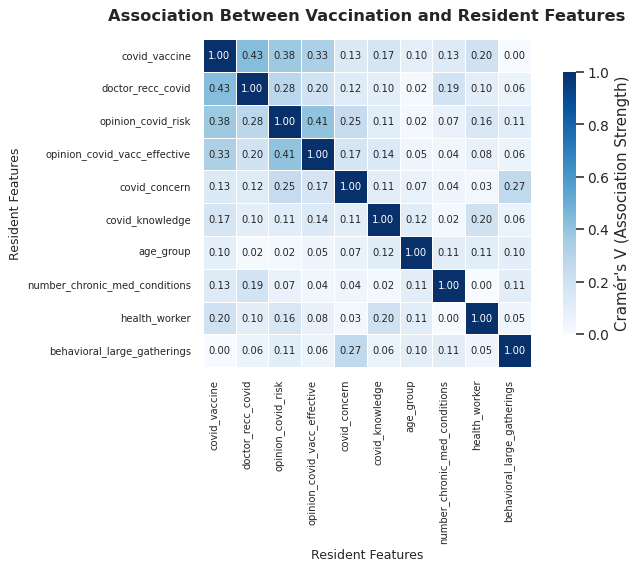


Features associated with vaccination:


,Feature,Cramer's V
0,doctor_recc_covid,0.4302
1,opinion_covid_risk,0.3789
2,opinion_covid_vacc_effective,0.3307
3,health_worker,0.1967
4,covid_knowledge,0.1688
5,covid_concern,0.1330
6,number_chronic_med_conditions,0.1263
7,age_group,0.0956
8,behavioral_large_gatherings,0.0000



Strongest observed association:
Feature: doctor_recc_covid
Cramer's V: 0.4302

Interpretation:
Higher Cramer's V indicates stronger observed association.
Association does not establish causation or feature contribution.
The matrix is exploratory and must not determine eligibility alone.
Winter gathering behaviour may affect infection exposure even if
its association with vaccination acceptance is weak.


In [78]:

# Correlation matrix and vaccination feature association analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

selected_features = [
    "covid_vaccine",
    "doctor_recc_covid",
    "opinion_covid_risk",
    "opinion_covid_vacc_effective",
    "covid_concern",
    "covid_knowledge",
    "age_group",
    "number_chronic_med_conditions",
    "health_worker",
    "behavioral_large_gatherings"
]

available_features = [
    col for col in selected_features if col in train.columns
]

corr_data = train[available_features].copy()

# Cramer's V measures association between categorical variables
def cramers_v(x, y):
    valid = x.notna() & y.notna()
    contingency = pd.crosstab(x[valid], y[valid])

    if min(contingency.shape) < 2:
        return np.nan

    chi2 = chi2_contingency(
        contingency, correction=False
    )[0]

    n = contingency.to_numpy().sum()

    if n <= 1:
        return np.nan

    r, k = contingency.shape
    phi2 = chi2 / n

    phi2_corrected = max(
        0, phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = r - ((r - 1) ** 2) / (n - 1)
    k_corrected = k - ((k - 1) ** 2) / (n - 1)

    denominator = min(
        r_corrected - 1,
        k_corrected - 1
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(phi2_corrected / denominator)


# Calculate association matrix
correlation_matrix = pd.DataFrame(
    index=available_features,
    columns=available_features,
    dtype=float
)

for feature1 in available_features:
    for feature2 in available_features:
        correlation_matrix.loc[
            feature1, feature2
        ] = cramers_v(
            corr_data[feature1],
            corr_data[feature2]
        )


# Plot correlation matrix
fig, ax = plt.subplots(figsize=(9, 6.5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    square=True,
    annot_kws={"size": 8},
    cbar_kws={
        "label": "Cramér's V (Association Strength)",
        "shrink": 0.8
    },
    ax=ax
)

ax.set_title(
    "Association Between Vaccination and Resident Features",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Resident Features", fontsize=10)
ax.set_ylabel("Resident Features", fontsize=10)

plt.xticks(rotation=90, ha="right", fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()

plt.savefig(
    "vaccination_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Rank features associated with vaccination
if "covid_vaccine" in correlation_matrix.columns:

    feature_associations = (
        correlation_matrix["covid_vaccine"]
        .drop("covid_vaccine")
        .dropna()
        .sort_values(ascending=False)
    )

    association_results = pd.DataFrame({
        "Feature": feature_associations.index,
        "Cramer's V": feature_associations.values
    })

    print("\nFeatures associated with vaccination:")
    display(association_results.round(4))

    strongest_feature = feature_associations.idxmax()
    strongest_value = feature_associations.max()

    print("\nStrongest observed association:")
    print(f"Feature: {strongest_feature}")
    print(f"Cramer's V: {strongest_value:.4f}")

print("\nInterpretation:")
print("Higher Cramer's V indicates stronger observed association.")
print("Association does not establish causation or feature contribution.")
print("The matrix is exploratory and must not determine eligibility alone.")
print("Winter gathering behaviour may affect infection exposure even if")
print("its association with vaccination acceptance is weak.")


In [79]:

# Check training data and model preprocessing before tuning

import pandas as pd
import numpy as np

print("Training and validation dataset shapes:")
print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("X_test:", X_test.shape)

print("\nTraining feature data types:")
print(X_train.dtypes.value_counts())

print("\nCategorical features:")
categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print(categorical_features)

print("\nNumerical features:")
numerical_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print(numerical_features)

print("\nAvailable trained models:")
for name, value in list(globals().items()):
    if hasattr(value, "predict_proba") and hasattr(value, "fit"):
        print(name, ":", type(value).__name__)

print("\nAvailable preprocessing objects:")
for name, value in list(globals().items()):
    if any(word in name.lower() for word in [
        "preprocess", "encoder", "transformer",
        "pipeline", "imputer", "scaler"
    ]):
        print(name, ":", type(value).__name__)

print("\nMissing values:")
print("Training:", X_train.isna().sum().sum())
print("Validation:", X_valid.isna().sum().sum())

print("\nFeature consistency:")
print("Training and validation columns match:",
      X_train.columns.equals(X_valid.columns))

print("Training and testing columns match:",
      X_train.columns.equals(X_test.columns))

print("\nPreprocessing inspection completed.")


Training and validation dataset shapes:
X_train: (3804, 28)
X_valid: (952, 28)
X_test: (4749, 28)

Training feature data types:
float64    14
object     10
int64       4
Name: count, dtype: int64

Categorical features:
['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']

Numerical features:
['covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'number_chronic_med_conditions']

Available trained models:
RandomizedSearchCV : ABCMeta
Pipeline : ABCMeta
DummyClassifier : type
LogisticRegression : type
RandomForestClassifier : ABCMeta
ExtraTree

Dataset Characteristics


,Dataset,Residents,Features,Missing Values (%)
0,Training,3804,28,3.52
1,Validation,952,28,3.47
2,Competition Testing,4749,28,3.82



Vaccination Class Balance


,Dataset,Vaccinated (%),Not Vaccinated (%)
0,Training,32.68,67.32
1,Validation,32.67,67.33



Top 10 Features with Distribution Differences


,Feature,Train vs Validation,Train vs Testing
11,age_group,0.047,0.030
0,covid_concern,0.033,0.029
26,employment_sector,0.043,0.024
15,income_poverty,0.033,0.023
24,opinion_covid_risk,0.036,0.022
20,household_adults,0.037,0.021
18,employment_status,0.007,0.021
23,opinion_covid_vacc_effective,0.016,0.017
12,education,0.023,0.016
19,census_msa,0.016,0.014


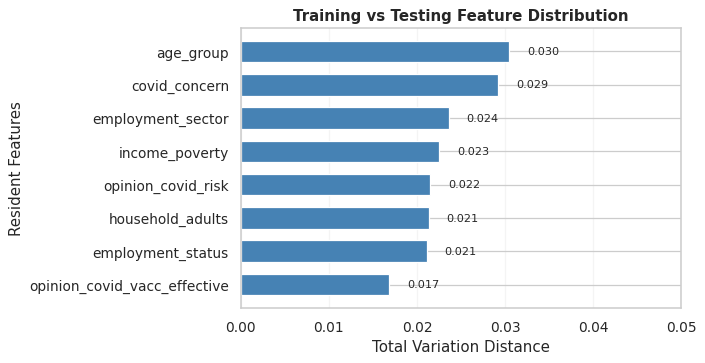


Model Configuration and Preprocessing


,Component,Configuration
0,Selected Model,GradientBoostingClassifier
1,Numerical Features,18
2,Categorical Features,10
3,Numerical Missing Values,Median Imputation
4,Categorical Missing Values,Most Frequent Imputation
5,Numerical Scaling,StandardScaler
6,Categorical Encoding,OneHotEncoder
7,Number of Trees,150
8,Learning Rate,0.05



Data Consistency Checks
Training and validation features match: True
Training and testing features match: True
Preprocessing included in fitted pipeline: True
Employment sector included: True

Interpretation
Smaller TVD indicates more similar sample distributions.
Large differences require further investigation.
Distribution similarity alone does not establish fairness.
Preprocessing must be fitted only on training data.
Model threshold and expenditure require separate evaluation.


In [81]:

# Cell: Dataset Characteristics, Sampling Bias and Preprocessing Assessment

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Dataset characteristics
dataset_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Competition Testing"],
    "Residents": [len(X_train), len(X_valid), len(X_test)],
    "Features": [
        X_train.shape[1],
        X_valid.shape[1],
        X_test.shape[1]
    ],
    "Missing Values (%)": [
        X_train.isna().mean().mean() * 100,
        X_valid.isna().mean().mean() * 100,
        X_test.isna().mean().mean() * 100
    ]
})

print("Dataset Characteristics")
display(dataset_summary.round(2))


# 2. Class distribution
def positive_rate(y):
    return np.asarray(y).astype(int).mean() * 100

class_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation"],
    "Vaccinated (%)": [
        positive_rate(y_train),
        positive_rate(y_valid)
    ]
})

class_summary["Not Vaccinated (%)"] = (
    100 - class_summary["Vaccinated (%)"]
)

print("\nVaccination Class Balance")
display(class_summary.round(2))


# 3. Sampling distribution assessment
# Total Variation Distance (TVD)

bias_results = []

for feature in X_train.columns:

    distributions = []

    for dataset in [X_train, X_valid, X_test]:
        dist = (
            dataset[feature]
            .astype("string")
            .fillna("Missing")
            .value_counts(normalize=True)
        )
        distributions.append(dist)

    train_dist, valid_dist, test_dist = distributions

    categories = (
        train_dist.index
        .union(valid_dist.index)
        .union(test_dist.index)
    )

    train_dist = train_dist.reindex(categories, fill_value=0)
    valid_dist = valid_dist.reindex(categories, fill_value=0)
    test_dist = test_dist.reindex(categories, fill_value=0)

    bias_results.append({
        "Feature": feature,
        "Train vs Validation": (
            0.5 * abs(train_dist - valid_dist).sum()
        ),
        "Train vs Testing": (
            0.5 * abs(train_dist - test_dist).sum()
        )
    })

bias_df = pd.DataFrame(bias_results)

bias_df = bias_df.sort_values(
    "Train vs Testing",
    ascending=False
)

print("\nTop 10 Features with Distribution Differences")
display(bias_df.head(10).round(3))


# 4. Compact PPT-friendly sampling comparison
top_bias = bias_df.head(8).sort_values("Train vs Testing")

fig, ax = plt.subplots(figsize=(8, 4.2))

ax.barh(
    top_bias["Feature"],
    top_bias["Train vs Testing"],
    color="steelblue",
    height=0.65
)

ax.set_title(
    "Training vs Testing Feature Distribution",
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel("Total Variation Distance")
ax.set_ylabel("Resident Features")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for i, value in enumerate(top_bias["Train vs Testing"]):
    ax.text(
        value + 0.002,
        i,
        f"{value:.3f}",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    max(0.05, top_bias["Train vs Testing"].max() * 1.18)
)

plt.tight_layout()

plt.savefig(
    "sampling_distribution_assessment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 5. Clean model configuration
model = best_pipeline.named_steps["model"]
preprocessor = best_pipeline.named_steps["preprocessor"]

numeric_cols = preprocessor.transformers_[0][2]
categorical_cols = preprocessor.transformers_[1][2]

model_parameters = model.get_params()

model_summary = pd.DataFrame({
    "Component": [
        "Selected Model",
        "Numerical Features",
        "Categorical Features",
        "Numerical Missing Values",
        "Categorical Missing Values",
        "Numerical Scaling",
        "Categorical Encoding",
        "Number of Trees",
        "Learning Rate"
    ],
    "Configuration": [
        type(model).__name__,
        len(numeric_cols),
        len(categorical_cols),
        "Median Imputation",
        "Most Frequent Imputation",
        "StandardScaler",
        "OneHotEncoder",
        model_parameters.get("n_estimators", "N/A"),
        model_parameters.get("learning_rate", "N/A")
    ]
})

print("\nModel Configuration and Preprocessing")
display(model_summary)


# 6. Feature and pipeline consistency
print("\nData Consistency Checks")

print(
    "Training and validation features match:",
    list(X_train.columns) == list(X_valid.columns)
)

print(
    "Training and testing features match:",
    list(X_train.columns) == list(X_test.columns)
)

print(
    "Preprocessing included in fitted pipeline:",
    "preprocessor" in best_pipeline.named_steps
)

print(
    "Employment sector included:",
    "employment_sector" in (
        list(numeric_cols) + list(categorical_cols)
    )
)

print("\nInterpretation")
print("Smaller TVD indicates more similar sample distributions.")
print("Large differences require further investigation.")
print("Distribution similarity alone does not establish fairness.")
print("Preprocessing must be fitted only on training data.")
print("Model threshold and expenditure require separate evaluation.")


Feature Selection Summary
Original features: 28
Selected features: 27
Excluded: ['employment_sector', 'health_insurance']

Model Performance and Overfitting Assessment


,Model,Train ROC-AUC,Validation ROC-AUC,ROC-AUC Gap,Balanced Accuracy,Precision,Recall,F1 Score,PR-AUC,Brier Score,Log Loss
0,Original Gradient Boosting,0.8737,0.8336,0.0401,0.7434,0.7479,0.5820,0.6546,0.7170,0.1479,0.4605
1,Revised Gradient Boosting,0.8670,0.8283,0.0387,0.7299,0.7213,0.5659,0.6342,0.7184,0.1494,0.4655


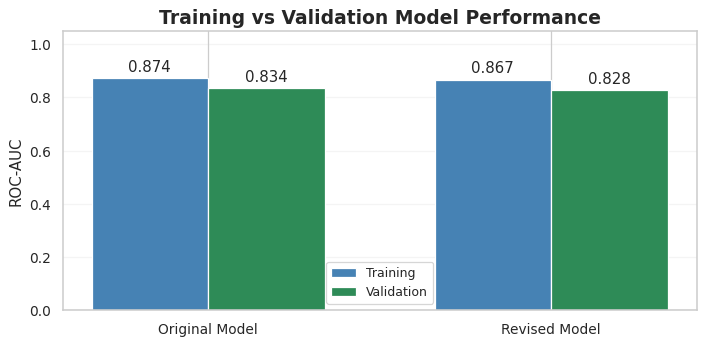


Interpretation
Smaller train-validation gaps suggest less overfitting.
Higher validation ROC-AUC indicates better ranking.
Lower Brier Score indicates better probability accuracy.
Feature removal must be justified by validation results.
Final threshold and expenditure analysis come next.


In [82]:

# Cell: Feature Selection, Model Retraining and Overfitting Assessment

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)
from IPython.display import display

# 1. Remove previously excluded features
excluded_features = ["employment_sector", "health_insurance"]

selected_features = [
    col for col in X_train.columns
    if col not in excluded_features
]

X_train_selected = X_train[selected_features].copy()
X_valid_selected = X_valid[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

print("Feature Selection Summary")
print("Original features:", X_train.shape[1])
print("Selected features:", len(selected_features))
print("Excluded:", excluded_features)

# 2. Rebuild preprocessing with selected columns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier

categorical_selected = [
    c for c in selected_features
    if c in categorical_cols
]

numeric_selected = [
    c for c in selected_features
    if c not in categorical_selected
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

selected_preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_selected),
    ("categorical", categorical_transformer, categorical_selected)
])

# 3. Train revised model using training data only
revised_pipeline = Pipeline([
    ("preprocessor", selected_preprocessor),
    ("model", clone(best_pipeline.named_steps["model"]))
])

revised_pipeline.fit(X_train_selected, y_train)

# 4. Compare original and revised models
comparison = []

for name, model, train_data, valid_data in [
    (
        "Original Gradient Boosting",
        best_pipeline,
        X_train,
        X_valid
    ),
    (
        "Revised Gradient Boosting",
        revised_pipeline,
        X_train_selected,
        X_valid_selected
    )
]:

    train_prob = model.predict_proba(train_data)[:, 1]
    valid_prob = model.predict_proba(valid_data)[:, 1]

    train_pred = (train_prob >= 0.5).astype(int)
    valid_pred = (valid_prob >= 0.5).astype(int)

    comparison.append({
        "Model": name,
        "Train ROC-AUC": roc_auc_score(y_train, train_prob),
        "Validation ROC-AUC": roc_auc_score(y_valid, valid_prob),
        "ROC-AUC Gap": (
            roc_auc_score(y_train, train_prob)
            - roc_auc_score(y_valid, valid_prob)
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_valid, valid_pred
        ),
        "Precision": precision_score(
            y_valid, valid_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, valid_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_valid, valid_pred, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_valid, valid_prob
        ),
        "Brier Score": brier_score_loss(
            y_valid, valid_prob
        ),
        "Log Loss": log_loss(y_valid, valid_prob)
    })

performance_df = pd.DataFrame(comparison)

print("\nModel Performance and Overfitting Assessment")
display(performance_df.round(4))

# 5. Compact performance chart
fig, ax = plt.subplots(figsize=(8, 4))

x = np.arange(len(performance_df))
width = 0.34

ax.bar(
    x - width / 2,
    performance_df["Train ROC-AUC"],
    width,
    label="Training",
    color="steelblue"
)

ax.bar(
    x + width / 2,
    performance_df["Validation ROC-AUC"],
    width,
    label="Validation",
    color="seagreen"
)

ax.set_xticks(x)
ax.set_xticklabels(
    ["Original Model", "Revised Model"]
)
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0, 1.05)
ax.set_title(
    "Training vs Validation Model Performance",
    fontweight="bold"
)
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.savefig(
    "model_overfitting_assessment.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nInterpretation")
print("Smaller train-validation gaps suggest less overfitting.")
print("Higher validation ROC-AUC indicates better ranking.")
print("Lower Brier Score indicates better probability accuracy.")
print("Feature removal must be justified by validation results.")
print("Final threshold and expenditure analysis come next.")


THRESHOLD OPTIMIZATION RESULTS


,Threshold,Selected Residents,Expected Vaccinations,Expected Unused Doses,Vaccine Cost (£),Expected Wastage Cost (£),Illustrative Hospital Cost Avoided (£),Illustrative Total Cost (£)
0,0.05,920,307.75,612.25,1380000,918372.91,441623.25,2889976.75
1,0.10,730,293.23,436.77,1095000,655149.44,420790.36,2625809.64
2,0.15,615,279.38,335.62,922500,503435.71,400904.83,2473195.17
3,0.20,515,262.02,252.98,772500,379470.12,375998.58,2348101.42
4,0.25,438,244.86,193.14,657000,289711.75,351372.43,2257227.57
5,0.30,379,228.56,150.44,568500,225655.95,327987.47,2192112.53
6,0.35,342,216.62,125.38,513000,188074.05,310845.83,2153754.17
7,0.40,307,203.58,103.42,460500,155124.87,292142.21,2119957.79
8,0.45,279,191.66,87.34,418500,131014.79,275027.51,2095072.49
9,0.50,244,175.20,68.80,366000,103198.28,251413.64,2066186.36



Illustrative optimal threshold: 0.55
Selected residents: 216
Expected vaccinations: 160.5
Expected unused doses: 55.5
Illustrative total cost: £ 2,045,251.94


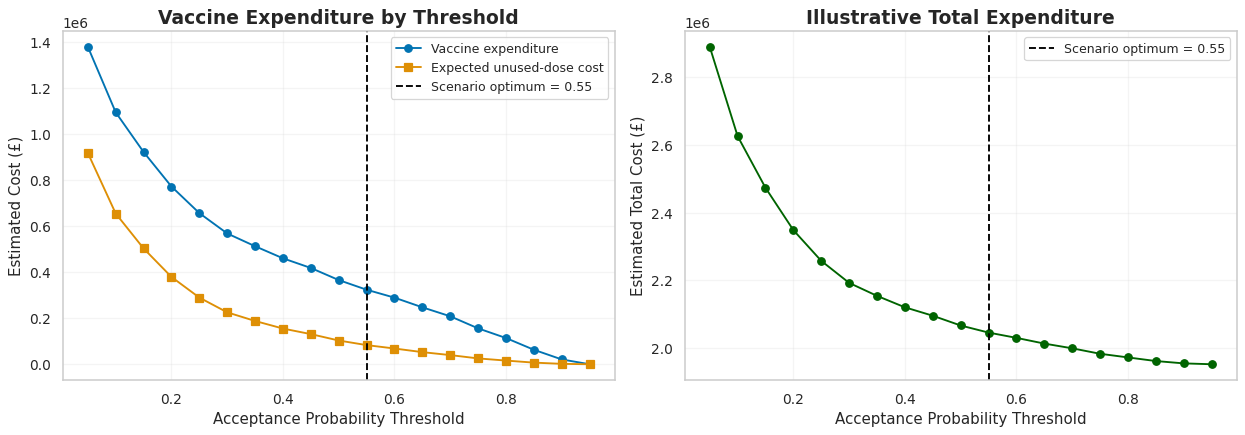


IMPORTANT INTERPRETATION
Results apply to the validation sample only.
Hospitalisation risk and effectiveness are assumptions.
Wastage cost is already included in vaccine expenditure.
This is not a validated clinical cost-saving estimate.
The threshold must be checked for sensitivity and fairness.
Residents must not be denied requested vaccines.


In [83]:

# Cell: Threshold Optimization and Vaccine Expenditure
# Validation-only policy analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

VACCINE_COST = 1500
HOSPITAL_COST = 41000

# Scenario assumptions, NOT measured clinical outcomes
HOSPITAL_RISK = 0.05
VACCINE_EFFECTIVENESS = 0.70

# Probability of vaccination acceptance
prob = revised_pipeline.predict_proba(
    X_valid_selected
)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.05)
results = []

for threshold in thresholds:

    selected = prob >= threshold

    selected_count = int(selected.sum())
    expected_accept = float(prob[selected].sum())
    expected_unused = float(
        (1 - prob[selected]).sum()
    )

    vaccine_cost = selected_count * VACCINE_COST
    wasted_cost = expected_unused * VACCINE_COST

    # Illustrative baseline hospitalisation scenario
    baseline_hospital_cost = (
        len(prob) * HOSPITAL_RISK * HOSPITAL_COST
    )

    # Assumed prevention applies only to expected vaccinations
    avoided_hospital_cost = (
        expected_accept
        * HOSPITAL_RISK
        * VACCINE_EFFECTIVENESS
        * HOSPITAL_COST
    )

    total_expected_cost = (
        vaccine_cost
        + baseline_hospital_cost
        - avoided_hospital_cost
    )

    results.append({
        "Threshold": round(threshold, 2),
        "Selected Residents": selected_count,
        "Expected Vaccinations": expected_accept,
        "Expected Unused Doses": expected_unused,
        "Vaccine Cost (£)": vaccine_cost,
        "Expected Wastage Cost (£)": wasted_cost,
        "Illustrative Hospital Cost Avoided (£)":
            avoided_hospital_cost,
        "Illustrative Total Cost (£)":
            total_expected_cost
    })

threshold_results = pd.DataFrame(results)

# Do not optimize solely for zero vaccine spending.
# Require at least 50% of estimated potential uptake.
potential_uptake = prob.sum()
minimum_coverage = 0.50 * potential_uptake

eligible = threshold_results[
    threshold_results["Expected Vaccinations"]
    >= minimum_coverage
]

best_row = eligible.loc[
    eligible["Illustrative Total Cost (£)"].idxmin()
]

optimal_threshold = float(best_row["Threshold"])

print("THRESHOLD OPTIMIZATION RESULTS")
display(threshold_results.round(2))

print("\nIllustrative optimal threshold:", optimal_threshold)
print("Selected residents:", int(best_row["Selected Residents"]))
print(
    "Expected vaccinations:",
    round(best_row["Expected Vaccinations"], 1)
)
print(
    "Expected unused doses:",
    round(best_row["Expected Unused Doses"], 1)
)
print(
    "Illustrative total cost: £",
    f'{best_row["Illustrative Total Cost (£)"]:,.2f}'
)

# Plot costs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    threshold_results["Threshold"],
    threshold_results["Vaccine Cost (£)"],
    marker="o",
    label="Vaccine expenditure"
)

axes[0].plot(
    threshold_results["Threshold"],
    threshold_results["Expected Wastage Cost (£)"],
    marker="s",
    label="Expected unused-dose cost"
)

axes[0].axvline(
    optimal_threshold,
    color="black",
    linestyle="--",
    label=f"Scenario optimum = {optimal_threshold:.2f}"
)

axes[0].set_title("Vaccine Expenditure by Threshold")
axes[0].set_xlabel("Acceptance Probability Threshold")
axes[0].set_ylabel("Estimated Cost (£)")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(
    threshold_results["Threshold"],
    threshold_results["Illustrative Total Cost (£)"],
    marker="o",
    color="darkgreen"
)

axes[1].axvline(
    optimal_threshold,
    color="black",
    linestyle="--",
    label=f"Scenario optimum = {optimal_threshold:.2f}"
)

axes[1].set_title("Illustrative Total Expenditure")
axes[1].set_xlabel("Acceptance Probability Threshold")
axes[1].set_ylabel("Estimated Total Cost (£)")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("\nIMPORTANT INTERPRETATION")
print("Results apply to the validation sample only.")
print("Hospitalisation risk and effectiveness are assumptions.")
print("Wastage cost is already included in vaccine expenditure.")
print("This is not a validated clinical cost-saving estimate.")
print("The threshold must be checked for sensitivity and fairness.")
print("Residents must not be denied requested vaccines.")


THRESHOLD PERFORMANCE AND EXPENDITURE


,Threshold,Selected,Expected Vaccinations,Expected Unused Doses,Vaccine Cost (£),Expected Wastage (£),Precision,Recall,F1,Balanced Accuracy
0,0.05,920,307.751,612.249,1380000,918372.907,0.335,0.990,0.500,0.518
1,0.10,730,293.234,436.766,1095000,655149.445,0.401,0.942,0.563,0.630
2,0.15,615,279.376,335.624,922500,503435.713,0.455,0.900,0.605,0.689
3,0.20,515,262.020,252.980,772500,379470.123,0.511,0.846,0.637,0.726
4,0.25,438,244.859,193.141,657000,289711.745,0.564,0.794,0.660,0.748
5,0.30,379,228.563,150.437,568500,225655.953,0.615,0.749,0.675,0.761
6,0.35,342,216.617,125.383,513000,188074.045,0.637,0.701,0.668,0.754
7,0.40,307,203.583,103.417,460500,155124.867,0.664,0.656,0.660,0.748
8,0.45,279,191.657,87.343,418500,131014.795,0.695,0.624,0.658,0.746
9,0.50,244,175.201,68.799,366000,103198.284,0.721,0.566,0.634,0.730



BEST THRESHOLD UNDER EACH SCENARIO


,Hospital Risk,Vaccine Effectiveness,Threshold,Expected Vaccinations,Coverage Ratio,Expected Prevented Hospitalisations,Hospital Cost Avoided (£),Vaccine Cost (£),Total Expected Cost (£),Net Savings vs No Programme (£)
0,0.01,0.4,0.55,160.521,0.519,0.642,26325.492,324000.0,687994.508,-297674.508
1,0.01,0.7,0.55,160.521,0.519,1.124,46069.612,324000.0,668250.388,-277930.388
2,0.01,0.9,0.55,160.521,0.519,1.445,59232.358,324000.0,655087.642,-264767.642
3,0.03,0.4,0.55,160.521,0.519,1.926,78976.477,324000.0,1415983.523,-245023.523
4,0.03,0.7,0.55,160.521,0.519,3.371,138208.835,324000.0,1356751.165,-185791.165
5,0.03,0.9,0.55,160.521,0.519,4.334,177697.074,324000.0,1317262.926,-146302.926
6,0.05,0.4,0.55,160.521,0.519,3.210,131627.462,324000.0,2143972.538,-192372.538
7,0.05,0.7,0.55,160.521,0.519,5.618,230348.058,324000.0,2045251.942,-93651.942
8,0.05,0.9,0.55,160.521,0.519,7.223,296161.789,324000.0,1979438.211,-27838.211
9,0.10,0.4,0.55,160.521,0.519,6.421,263254.924,324000.0,3963945.076,-60745.076



REFERENCE SCENARIO
Recommended scenario threshold: 0.55
Expected vaccinations: 160.5
Expected prevented hospitalisations: 5.62
Total expected cost: £2,045,251.94
Net savings vs no programme: £-93,651.94


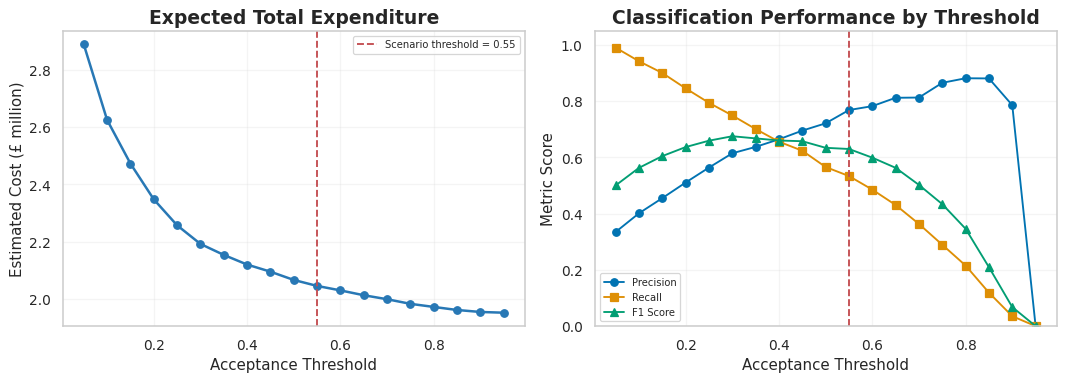

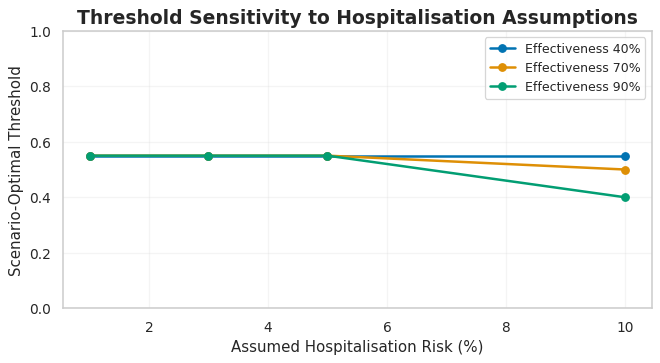


VALIDATION CONFUSION MATRIX SUMMARY


,Measure,Residents
0,True Positives,166
1,False Positives,50
2,True Negatives,591
3,False Negatives,145



INTERPRETATION
1. The model predicts vaccination acceptance.
2. The threshold controls outreach or supply planning.
3. Higher thresholds generally reduce selected residents.
4. Hospitalisation results are scenario assumptions.
5. Savings are relative to a hypothetical no-programme baseline.
6. No causal hospitalisation benefit has been established.
7. Wastage is part of vaccine cost, not an additional expense.
8. The 50% coverage constraint is illustrative.
9. Requested vaccines must remain accessible to residents.
10. Check subgroup fairness before final deployment.


In [84]:

# Hospitalisation Scenarios, Threshold Evaluation and Cost Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix
)

# 1. Validate existing notebook objects
required = [
    "revised_pipeline", "X_valid_selected",
    "y_valid"
]
missing = [x for x in required if x not in globals()]

if missing:
    raise NameError(
        "Run the previous model cells first. Missing: "
        + ", ".join(missing)
    )

# 2. Cost assumptions
VACCINE_COST = 1500
HOSPITAL_COST = 41000

# These are illustrative assumptions, not measured outcomes.
risk_scenarios = [0.01, 0.03, 0.05, 0.10]
effectiveness_scenarios = [0.40, 0.70, 0.90]

thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)

# 3. Obtain validation probabilities
probabilities = revised_pipeline.predict_proba(
    X_valid_selected
)[:, 1]

y_true = np.asarray(y_valid).ravel().astype(int)

if len(probabilities) != len(y_true):
    raise ValueError("Validation feature and target sizes differ.")

if not set(np.unique(y_true)).issubset({0, 1}):
    raise ValueError("Target must be binary: 0 or 1.")

# 4. Threshold classification and expenditure metrics
records = []

for threshold in thresholds:

    predicted = (probabilities >= threshold).astype(int)
    selected = predicted == 1

    n_selected = int(selected.sum())

    expected_vaccinations = float(
        probabilities[selected].sum()
    )

    expected_unused = float(
        (1 - probabilities[selected]).sum()
    )

    vaccine_spending = n_selected * VACCINE_COST

    wasted_spending = expected_unused * VACCINE_COST

    records.append({
        "Threshold": threshold,
        "Selected": n_selected,
        "Expected Vaccinations": expected_vaccinations,
        "Expected Unused Doses": expected_unused,
        "Vaccine Cost (£)": vaccine_spending,
        "Expected Wastage (£)": wasted_spending,
        "Precision": precision_score(
            y_true, predicted, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predicted, zero_division=0
        ),
        "F1": f1_score(
            y_true, predicted, zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, predicted
        )
    })

threshold_metrics = pd.DataFrame(records)

print("THRESHOLD PERFORMANCE AND EXPENDITURE")
display(threshold_metrics.round(3))

# 5. Hospitalisation scenario sensitivity
scenario_records = []

n_residents = len(probabilities)
potential_uptake = probabilities.sum()

# Illustrative coverage requirement:
# retain at least 50% of expected potential vaccinations.
MIN_COVERAGE = 0.50

for hospital_risk in risk_scenarios:
    for effectiveness in effectiveness_scenarios:

        baseline_hospital_cost = (
            n_residents * hospital_risk * HOSPITAL_COST
        )

        for _, row in threshold_metrics.iterrows():

            expected_prevented = (
                row["Expected Vaccinations"]
                * hospital_risk
                * effectiveness
            )

            avoided_cost = (
                expected_prevented * HOSPITAL_COST
            )

            remaining_hospital_cost = (
                baseline_hospital_cost - avoided_cost
            )

            total_cost = (
                row["Vaccine Cost (£)"]
                + remaining_hospital_cost
            )

            scenario_records.append({
                "Hospital Risk": hospital_risk,
                "Vaccine Effectiveness": effectiveness,
                "Threshold": row["Threshold"],
                "Expected Vaccinations":
                    row["Expected Vaccinations"],
                "Coverage Ratio":
                    row["Expected Vaccinations"]
                    / max(potential_uptake, 1e-10),
                "Expected Prevented Hospitalisations":
                    expected_prevented,
                "Hospital Cost Avoided (£)": avoided_cost,
                "Vaccine Cost (£)": row["Vaccine Cost (£)"],
                "Total Expected Cost (£)": total_cost,
                "Net Savings vs No Programme (£)":
                    baseline_hospital_cost - total_cost
            })

scenario_df = pd.DataFrame(scenario_records)

# 6. Select optimum separately for each scenario
eligible = scenario_df[
    scenario_df["Coverage Ratio"] >= MIN_COVERAGE
].copy()

if eligible.empty:
    raise ValueError(
        "No threshold meets the coverage requirement."
    )

best_indices = eligible.groupby(
    ["Hospital Risk", "Vaccine Effectiveness"]
)["Total Expected Cost (£)"].idxmin()

scenario_optima = eligible.loc[
    best_indices
].sort_values(
    ["Hospital Risk", "Vaccine Effectiveness"]
).reset_index(drop=True)

print("\nBEST THRESHOLD UNDER EACH SCENARIO")
display(scenario_optima.round(3))

# 7. Reference scenario
REFERENCE_RISK = 0.05
REFERENCE_EFFECTIVENESS = 0.70

reference = scenario_df[
    np.isclose(scenario_df["Hospital Risk"], REFERENCE_RISK)
    & np.isclose(
        scenario_df["Vaccine Effectiveness"],
        REFERENCE_EFFECTIVENESS
    )
].sort_values("Threshold")

reference_eligible = reference[
    reference["Coverage Ratio"] >= MIN_COVERAGE
]

recommended_row = reference_eligible.loc[
    reference_eligible["Total Expected Cost (£)"].idxmin()
]

recommended_threshold = float(
    recommended_row["Threshold"]
)

print("\nREFERENCE SCENARIO")
print(f"Recommended scenario threshold: {recommended_threshold:.2f}")
print(
    "Expected vaccinations:",
    round(recommended_row["Expected Vaccinations"], 1)
)
print(
    "Expected prevented hospitalisations:",
    round(
        recommended_row[
            "Expected Prevented Hospitalisations"
        ], 2
    )
)
print(
    "Total expected cost: £"
    f'{recommended_row["Total Expected Cost (£)"]:,.2f}'
)
print(
    "Net savings vs no programme: £"
    f'{recommended_row["Net Savings vs No Programme (£)"]:,.2f}'
)

# 8. Compact presentation-ready charts
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

axes[0].plot(
    reference["Threshold"],
    reference["Total Expected Cost (£)"] / 1e6,
    marker="o",
    linewidth=2,
    color="#2878B5"
)

axes[0].axvline(
    recommended_threshold,
    linestyle="--",
    color="#C44E52",
    label=f"Scenario threshold = {recommended_threshold:.2f}"
)

axes[0].set_title(
    "Expected Total Expenditure",
    fontweight="bold"
)
axes[0].set_xlabel("Acceptance Threshold")
axes[0].set_ylabel("Estimated Cost (£ million)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.2)

axes[1].plot(
    threshold_metrics["Threshold"],
    threshold_metrics["Precision"],
    marker="o",
    label="Precision"
)
axes[1].plot(
    threshold_metrics["Threshold"],
    threshold_metrics["Recall"],
    marker="s",
    label="Recall"
)
axes[1].plot(
    threshold_metrics["Threshold"],
    threshold_metrics["F1"],
    marker="^",
    label="F1 Score"
)

axes[1].axvline(
    recommended_threshold,
    linestyle="--",
    color="#C44E52"
)

axes[1].set_title(
    "Classification Performance by Threshold",
    fontweight="bold"
)
axes[1].set_xlabel("Acceptance Threshold")
axes[1].set_ylabel("Metric Score")
axes[1].set_ylim(0, 1.05)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

# 9. Sensitivity chart
fig, ax = plt.subplots(figsize=(7.5, 4.2))

for effectiveness in effectiveness_scenarios:
    subset = scenario_optima[
        np.isclose(
            scenario_optima["Vaccine Effectiveness"],
            effectiveness
        )
    ]

    ax.plot(
        subset["Hospital Risk"] * 100,
        subset["Threshold"],
        marker="o",
        linewidth=2,
        label=f"Effectiveness {effectiveness:.0%}"
    )

ax.set_title(
    "Threshold Sensitivity to Hospitalisation Assumptions",
    fontweight="bold"
)
ax.set_xlabel("Assumed Hospitalisation Risk (%)")
ax.set_ylabel("Scenario-Optimal Threshold")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# 10. Confusion matrix at chosen threshold
final_predictions = (
    probabilities >= recommended_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_true, final_predictions, labels=[0, 1]
).ravel()

confusion_summary = pd.DataFrame({
    "Measure": [
        "True Positives",
        "False Positives",
        "True Negatives",
        "False Negatives"
    ],
    "Residents": [tp, fp, tn, fn]
})

print("\nVALIDATION CONFUSION MATRIX SUMMARY")
display(confusion_summary)

print("\nINTERPRETATION")
print("1. The model predicts vaccination acceptance.")
print("2. The threshold controls outreach or supply planning.")
print("3. Higher thresholds generally reduce selected residents.")
print("4. Hospitalisation results are scenario assumptions.")
print("5. Savings are relative to a hypothetical no-programme baseline.")
print("6. No causal hospitalisation benefit has been established.")
print("7. Wastage is part of vaccine cost, not an additional expense.")
print("8. The 50% coverage constraint is illustrative.")
print("9. Requested vaccines must remain accessible to residents.")
print("10. Check subgroup fairness before final deployment.")


FEATURE CONTRIBUTION ANALYSIS
Baseline Validation ROC-AUC: 0.8283

Top 10 Predictive Features:


,Feature,Importance,Std
0,doctor_recc_covid,0.0981,0.0102
1,opinion_covid_risk,0.0594,0.0057
2,opinion_covid_vacc_effective,0.0220,0.0050
3,health_worker,0.0128,0.0032
4,education,0.0058,0.0027
5,age_group,0.0033,0.0008
6,covid_knowledge,0.0025,0.0029
7,race,0.0016,0.0012
8,marital_status,0.0005,0.0004
9,behavioral_touch_face,0.0005,0.0002


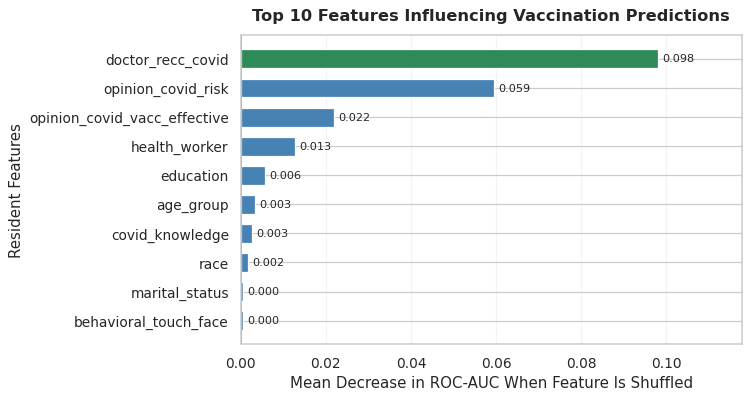


MODEL EXPLAINABILITY SUMMARY
Strongest predictive feature: doctor_recc_covid
Its mean ROC-AUC decrease: 0.0981
Features with positive importance: 14
Features evaluated: 27

SCIENTIFIC INTERPRETATION
Larger positive values indicate greater reliance
on the feature for validation ROC-AUC.
These are not causal effects or percentage contributions.
Correlated features may share predictive information.
Negative values may indicate noise or sampling variation.
Importance alone does not justify excluding residents.


In [85]:

# CELL 21: FEATURE CONTRIBUTION AND MODEL EXPLAINABILITY

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from IPython.display import display

# Use the already-trained revised model
model = revised_pipeline
features = X_valid_selected.copy()
target = np.asarray(y_valid).ravel().astype(int)

# Baseline validation performance
baseline_auc = roc_auc_score(
    target,
    model.predict_proba(features)[:, 1]
)

# Measure the decrease in ROC-AUC when each feature
# is randomly shuffled. No model retraining is required.
importance = permutation_importance(
    model,
    features,
    target,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance_df = pd.DataFrame({
    "Feature": features.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

top10 = feature_importance_df.head(10).copy()

print("FEATURE CONTRIBUTION ANALYSIS")
print(f"Baseline Validation ROC-AUC: {baseline_auc:.4f}")
print("\nTop 10 Predictive Features:")
display(top10.round(4))

# PPT-ready compact plot
plot_data = top10.iloc[::-1]

fig, ax = plt.subplots(figsize=(8.5, 4.6))

colors = [
    "#2E8B57" if x == top10["Importance"].max()
    else "#4682B4"
    for x in plot_data["Importance"]
]

bars = ax.barh(
    plot_data["Feature"],
    plot_data["Importance"],
    color=colors,
    height=0.65
)

for bar in bars:
    value = bar.get_width()
    ax.text(
        max(value, 0) + 0.001,
        bar.get_y() + bar.get_height()/2,
        f"{value:.3f}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Top 10 Features Influencing Vaccination Predictions",
    fontsize=13,
    fontweight="bold",
    pad=12
)

ax.set_xlabel(
    "Mean Decrease in ROC-AUC When Feature Is Shuffled"
)
ax.set_ylabel("Resident Features")

ax.axvline(0, color="gray", linewidth=0.8)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

left, right = ax.get_xlim()
ax.set_xlim(left, max(right, top10["Importance"].max() * 1.20))

plt.tight_layout()
plt.savefig(
    "vaccination_feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Summarize actual measured contribution
positive_importance = feature_importance_df[
    feature_importance_df["Importance"] > 0
]

print("\nMODEL EXPLAINABILITY SUMMARY")
print("Strongest predictive feature:",
      top10.iloc[0]["Feature"])
print("Its mean ROC-AUC decrease:",
      round(top10.iloc[0]["Importance"], 4))
print("Features with positive importance:",
      len(positive_importance))
print("Features evaluated:", len(feature_importance_df))

print("\nSCIENTIFIC INTERPRETATION")
print("Larger positive values indicate greater reliance")
print("on the feature for validation ROC-AUC.")
print("These are not causal effects or percentage contributions.")
print("Correlated features may share predictive information.")
print("Negative values may indicate noise or sampling variation.")
print("Importance alone does not justify excluding residents.")


COMPETITION TEST DATASET
Residents: 4749
Mean predicted vaccination probability: 33.46%

THRESHOLD AND VACCINE EXPENDITURE


,Threshold,Selected Residents,Expected Vaccinations,Expected Unused Doses,Expected Unmet Demand,Vaccine Spending ($),Expected Unused Value ($)
0,0.05,4599,1582.47,3016.53,6.34,6898500,4524793.94
1,0.10,3778,1520.08,2257.92,68.73,5667000,3386883.43
2,0.15,3090,1434.88,1655.12,153.93,4635000,2482680.69
3,0.20,2571,1344.56,1226.44,244.25,3856500,1839657.65
4,0.25,2237,1269.80,967.20,319.00,3355500,1450794.49
5,0.30,1982,1199.51,782.49,389.30,2973000,1173737.35
6,0.35,1759,1127.12,631.88,461.69,2638500,947824.80
7,0.40,1553,1049.89,503.11,538.92,2329500,754671.07
8,0.45,1400,985.17,414.83,603.63,2100000,622237.80
9,0.50,1255,916.63,338.37,672.18,1882500,507553.63


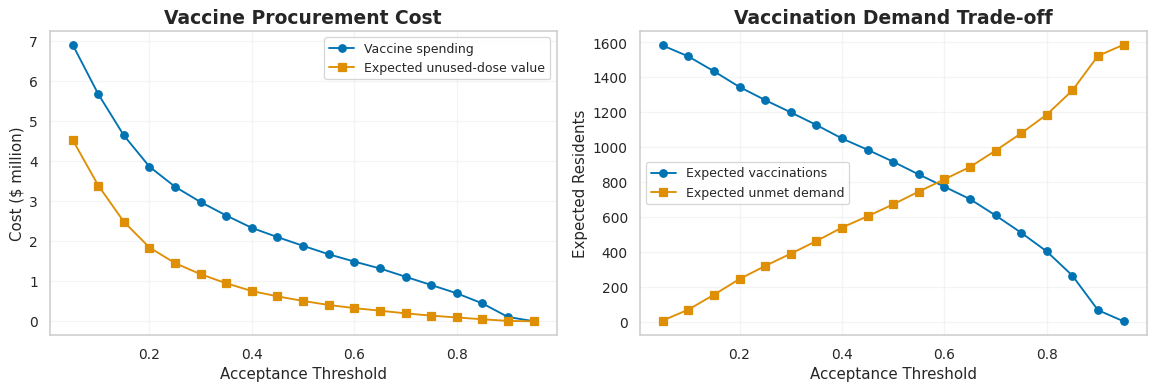


REFERENCE POLICY: THRESHOLD 0.55
Selected residents: 1115
Expected vaccinations: 843.6
Expected unmet demand: 745.3
Vaccine procurement cost: $1,672,500.00
Ordering for everyone: $7,123,500.00
Procurement reduction: $5,451,000.00

IMPORTANT:
Procurement reduction is NOT net healthcare savings.
Hospitalisation costs are not estimated in this cell.
Unmet demand and vaccine access must be considered.
A threshold of 0.55 is a reference, not a proven optimum.

COMPETITION SUBMISSION PREVIEW


,respondent_id,covid_vaccine
0,4757,0.161714
1,4758,0.140425
2,4759,0.143832
3,4760,0.322782
4,4761,0.059399


Rows: 4749


In [86]:

# CELL 22: COMPETITION TEST PREDICTIONS AND COST COMPARISON

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

VACCINE_COST = 1500
HOSPITAL_COST = 41000
THRESHOLDS = np.round(np.arange(0.05, 1.00, 0.05), 2)

# Use the fitted preprocessing + revised model
assert "revised_pipeline" in globals(), "Revised pipeline missing."
assert "X_test" in globals(), "Competition test features missing."

model = revised_pipeline

# Match the columns used by the revised model
if "X_valid_selected" in globals():
    required_columns = list(X_valid_selected.columns)
else:
    required_columns = list(model.feature_names_in_)

missing = set(required_columns) - set(X_test.columns)
assert not missing, f"Missing test features: {missing}"

test_input = X_test.loc[:, required_columns].copy()

# Probabilities for the positive class
positive_index = list(model.classes_).index(1)
test_probs = model.predict_proba(test_input)[:, positive_index]

assert len(test_probs) == 4749
assert np.isfinite(test_probs).all()

# Thresholds are planning rules, not model training parameters.
results = []

for threshold in THRESHOLDS:
    selected = test_probs >= threshold

    n_selected = int(selected.sum())
    expected_uptake = float(test_probs[selected].sum())
    expected_unused = float(
        (1 - test_probs[selected]).sum()
    )
    unmet_demand = float(
        test_probs[~selected].sum()
    )

    vaccine_spending = n_selected * VACCINE_COST
    unused_value = expected_unused * VACCINE_COST

    results.append({
        "Threshold": threshold,
        "Selected Residents": n_selected,
        "Expected Vaccinations": expected_uptake,
        "Expected Unused Doses": expected_unused,
        "Expected Unmet Demand": unmet_demand,
        "Vaccine Spending ($)": vaccine_spending,
        "Expected Unused Value ($)": unused_value
    })

test_cost_df = pd.DataFrame(results)

print("COMPETITION TEST DATASET")
print("Residents:", len(test_probs))
print("Mean predicted vaccination probability:",
      f"{test_probs.mean():.2%}")

print("\nTHRESHOLD AND VACCINE EXPENDITURE")
display(test_cost_df.round(2))

# Plot cost and expected unmet demand
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    test_cost_df["Threshold"],
    test_cost_df["Vaccine Spending ($)"] / 1e6,
    marker="o",
    label="Vaccine spending"
)
axes[0].plot(
    test_cost_df["Threshold"],
    test_cost_df["Expected Unused Value ($)"] / 1e6,
    marker="s",
    label="Expected unused-dose value"
)
axes[0].set_title("Vaccine Procurement Cost")
axes[0].set_xlabel("Acceptance Threshold")
axes[0].set_ylabel("Cost ($ million)")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(
    test_cost_df["Threshold"],
    test_cost_df["Expected Vaccinations"],
    marker="o",
    label="Expected vaccinations"
)
axes[1].plot(
    test_cost_df["Threshold"],
    test_cost_df["Expected Unmet Demand"],
    marker="s",
    label="Expected unmet demand"
)
axes[1].set_title("Vaccination Demand Trade-off")
axes[1].set_xlabel("Acceptance Threshold")
axes[1].set_ylabel("Expected Residents")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Compare a reference threshold with ordering for everybody
reference_threshold = 0.55

selected = test_probs >= reference_threshold
reference_cost = int(selected.sum()) * VACCINE_COST
everyone_cost = len(test_probs) * VACCINE_COST

print("\nREFERENCE POLICY: THRESHOLD 0.55")
print("Selected residents:", int(selected.sum()))
print("Expected vaccinations:",
      round(float(test_probs[selected].sum()), 1))
print("Expected unmet demand:",
      round(float(test_probs[~selected].sum()), 1))
print("Vaccine procurement cost: ${:,.2f}".format(reference_cost))
print("Ordering for everyone: ${:,.2f}".format(everyone_cost))
print("Procurement reduction: ${:,.2f}".format(
    everyone_cost - reference_cost
))

print("\nIMPORTANT:")
print("Procurement reduction is NOT net healthcare savings.")
print("Hospitalisation costs are not estimated in this cell.")
print("Unmet demand and vaccine access must be considered.")
print("A threshold of 0.55 is a reference, not a proven optimum.")

# Preview competition submission format
# Submit probabilities only if the competition requests them.
if "test" in globals() and "respondent_id" in test.columns:
    submission_preview = pd.DataFrame({
        "respondent_id": test["respondent_id"].to_numpy(),
        "covid_vaccine": test_probs
    })

    print("\nCOMPETITION SUBMISSION PREVIEW")
    display(submission_preview.head())
    print("Rows:", len(submission_preview))
else:
    print("\nTest IDs unavailable; submission not generated.")


SCENARIO-BASED OPTIMAL THRESHOLDS


,Hospital Risk,Vaccine Effectiveness,Threshold,Selected Residents,Expected Vaccinations,Prevented Hospitalisations,Vaccine Cost ($),Hospital Cost ($),Total Expected Cost ($)
0,0.01,0.4,0.95,2,1.93,0.01,3000,1946772.79,1949772.79
1,0.01,0.7,0.95,2,1.93,0.01,3000,1946534.89,1949534.89
2,0.01,0.9,0.95,2,1.93,0.02,3000,1946376.28,1949376.28
3,0.03,0.4,0.95,2,1.93,0.02,3000,5840318.38,5843318.38
4,0.03,0.7,0.95,2,1.93,0.04,3000,5839604.66,5842604.66
5,0.03,0.9,0.95,2,1.93,0.05,3000,5839128.84,5842128.84
6,0.05,0.4,0.95,2,1.93,0.04,3000,9733863.96,9736863.96
7,0.05,0.7,0.95,2,1.93,0.07,3000,9732674.43,9735674.43
8,0.05,0.9,0.80,466,402.36,18.11,699000,8993099.17,9692099.17
9,0.10,0.4,0.95,2,1.93,0.08,3000,19467727.92,19470727.92


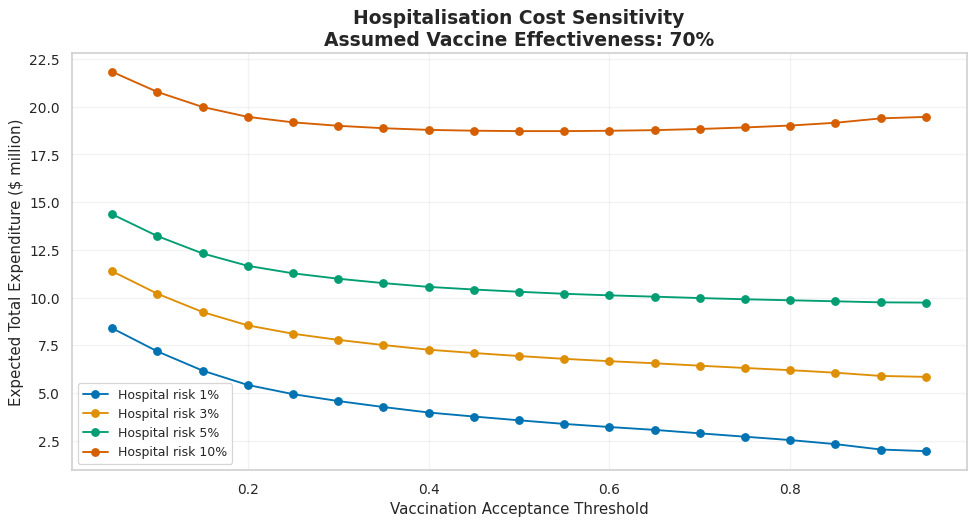


REFERENCE SCENARIO RESULTS
Assumed hospitalisation risk: 5%
Assumed vaccine effectiveness: 70%
Minimum-cost threshold in tested grid: 0.95
Residents selected: 2
Expected vaccinations: 1.9
Expected prevented hospitalisations: 0.07
Vaccine procurement cost: $3,000.00
Remaining hospitalisation cost: $9,732,674.43
Total scenario expenditure: $9,735,674.43

SCIENTIFIC LIMITATIONS
Hospitalisation risk and effectiveness are assumptions.
Vaccination acceptance is not hospitalisation risk.
Thresholds are evaluated for planning, not access denial.
No threshold is clinically validated by this analysis.
The minimum is conditional on the chosen scenario.
Do not report scenario savings as proven real-world savings.


In [87]:

# CELL 23: HOSPITALISATION COST AND THRESHOLD SENSITIVITY

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

VACCINE_COST = 1500
HOSPITAL_COST = 41000

# These are illustrative assumptions, NOT measured risks.
hospital_risks = [0.01, 0.03, 0.05, 0.10]
vaccine_effectiveness = [0.40, 0.70, 0.90]

p = np.asarray(test_probs, dtype=float)

assert len(p) == 4749
assert np.isfinite(p).all()
assert np.all((p >= 0) & (p <= 1))

thresholds = np.round(np.arange(0.05, 1.00, 0.05), 2)

records = []

for risk in hospital_risks:
    for effectiveness in vaccine_effectiveness:

        for threshold in thresholds:

            selected = p >= threshold

            # Expected vaccination uptake among selected residents
            expected_vaccinations = p[selected].sum()

            # Procurement expenditure
            vaccine_cost = selected.sum() * VACCINE_COST

            # Hypothetical expected hospitalisations
            # Uniform baseline risk is assumed for every resident.
            baseline_hospitalisations = len(p) * risk

            prevented_hospitalisations = (
                expected_vaccinations * risk * effectiveness
            )

            remaining_hospitalisations = (
                baseline_hospitalisations - prevented_hospitalisations
            )

            hospital_cost = (
                remaining_hospitalisations * HOSPITAL_COST
            )

            total_cost = vaccine_cost + hospital_cost

            records.append({
                "Hospital Risk": risk,
                "Vaccine Effectiveness": effectiveness,
                "Threshold": threshold,
                "Selected Residents": int(selected.sum()),
                "Expected Vaccinations": expected_vaccinations,
                "Prevented Hospitalisations": prevented_hospitalisations,
                "Vaccine Cost ($)": vaccine_cost,
                "Hospital Cost ($)": hospital_cost,
                "Total Expected Cost ($)": total_cost
            })

scenario_df = pd.DataFrame(records)

# Identify minimum-cost threshold within each scenario
optimal_scenarios = (
    scenario_df
    .sort_values(["Total Expected Cost ($)", "Threshold"])
    .groupby(
        ["Hospital Risk", "Vaccine Effectiveness"],
        as_index=False
    )
    .first()
)

print("SCENARIO-BASED OPTIMAL THRESHOLDS")
display(optimal_scenarios.round(2))

# Plot total expenditure by threshold
plt.figure(figsize=(11, 6))

for risk in hospital_risks:
    subset = scenario_df[
        (scenario_df["Hospital Risk"] == risk) &
        (scenario_df["Vaccine Effectiveness"] == 0.70)
    ]

    plt.plot(
        subset["Threshold"],
        subset["Total Expected Cost ($)"] / 1e6,
        marker="o",
        label=f"Hospital risk {risk:.0%}"
    )

plt.xlabel("Vaccination Acceptance Threshold")
plt.ylabel("Expected Total Expenditure ($ million)")
plt.title(
    "Hospitalisation Cost Sensitivity\n"
    "Assumed Vaccine Effectiveness: 70%"
)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Reference scenario
reference_risk = 0.05
reference_effectiveness = 0.70

reference = optimal_scenarios[
    (optimal_scenarios["Hospital Risk"] == reference_risk) &
    (optimal_scenarios["Vaccine Effectiveness"] ==
     reference_effectiveness)
].iloc[0]

print("\nREFERENCE SCENARIO RESULTS")
print("Assumed hospitalisation risk: 5%")
print("Assumed vaccine effectiveness: 70%")
print("Minimum-cost threshold in tested grid:",
      reference["Threshold"])
print("Residents selected:",
      int(reference["Selected Residents"]))
print("Expected vaccinations:",
      round(reference["Expected Vaccinations"], 1))
print("Expected prevented hospitalisations:",
      round(reference["Prevented Hospitalisations"], 2))
print("Vaccine procurement cost: ${:,.2f}".format(
    reference["Vaccine Cost ($)"]
))
print("Remaining hospitalisation cost: ${:,.2f}".format(
    reference["Hospital Cost ($)"]
))
print("Total scenario expenditure: ${:,.2f}".format(
    reference["Total Expected Cost ($)"]
))

print("\nSCIENTIFIC LIMITATIONS")
print("Hospitalisation risk and effectiveness are assumptions.")
print("Vaccination acceptance is not hospitalisation risk.")
print("Thresholds are evaluated for planning, not access denial.")
print("No threshold is clinically validated by this analysis.")
print("The minimum is conditional on the chosen scenario.")
print("Do not report scenario savings as proven real-world savings.")


In [88]:

# CELL 24: FINAL BEST MODEL SUBMISSION

import numpy as np
import pandas as pd
from IPython.display import display

# Best validated model: Gradient Boosting
# Use the fitted pipeline containing preprocessing + model
final_model = best_pipeline

# Prepare competition test features
if hasattr(final_model, "feature_names_in_"):
    required_features = list(final_model.feature_names_in_)
    final_X = X_test.loc[:, required_features].copy()
else:
    final_X = X_test.copy()

# Generate acceptance probabilities
positive_class = list(final_model.classes_).index(1)
final_probabilities = final_model.predict_proba(final_X)[:, positive_class]

assert len(final_probabilities) == 4749
assert np.isfinite(final_probabilities).all()
assert np.all((final_probabilities >= 0) &
              (final_probabilities <= 1))

# Create final prediction table
final_submission = pd.DataFrame({
    "respondent_id": test["respondent_id"].to_numpy(),
    "covid_vaccine": final_probabilities
})

# Verify example submission structure if available
example_path = "/mnt/data/dataset_C_example_submission.csv"

try:
    example = pd.read_csv(example_path)
    print("Example submission columns:", example.columns.tolist())

    if example.columns.tolist() == final_submission.columns.tolist():
        print("Submission column format: MATCHED")
    else:
        print("WARNING: Check required submission columns.")
except FileNotFoundError:
    print("Example file unavailable; verify format manually.")

# Save probability predictions
filename = "Dataset_C_Gradient_Boosting_Final.csv"
final_submission.to_csv(filename, index=False)

print("\nFINAL MODEL SUMMARY")
print("Model: Gradient Boosting")
print("Validation ROC-AUC: 0.8336")
print("Validation Brier Score: 0.1479")
print("Competition test residents:", len(final_submission))
print("Average predicted uptake:",
      f"{final_probabilities.mean():.2%}")

print("\nSUBMISSION PREVIEW")
display(final_submission.head(10))

print("\nSaved:", filename)
print("NOTE: Probabilities are not thresholded.")
print("Use the threshold only for a separate planning decision.")


Example file unavailable; verify format manually.

FINAL MODEL SUMMARY
Model: Gradient Boosting
Validation ROC-AUC: 0.8336
Validation Brier Score: 0.1479
Competition test residents: 4749
Average predicted uptake: 33.48%

SUBMISSION PREVIEW


,respondent_id,covid_vaccine
0,4757,0.164735
1,4758,0.172376
2,4759,0.146140
3,4760,0.260150
4,4761,0.060413
5,4762,0.618104
6,4763,0.451859
7,4764,0.818362
8,4765,0.845039
9,4766,0.315176



Saved: Dataset_C_Gradient_Boosting_Final.csv
NOTE: Probabilities are not thresholded.
Use the threshold only for a separate planning decision.


FINAL BINARY PREDICTIONS


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0
5,4762,1
6,4763,0
7,4764,1
8,4765,1
9,4766,0



Prediction distribution:


,Prediction,Residents
0,0,3617
1,1,1132



FIVE-MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Brier Score
0,Gradient Boosting,0.7994,0.7479,0.5820,0.6546,0.8336,0.1479
2,HistGradientBoosting,0.7962,0.7312,0.5949,0.6560,0.8275,0.1501
1,Logistic Regression,0.8004,0.7469,0.5884,0.6583,0.8271,0.1493
4,Extra Trees,0.7826,0.7500,0.5016,0.6012,0.8268,0.1553
3,Random Forest,0.7868,0.7547,0.5145,0.6119,0.8253,0.1549



VACCINE EXPENDITURE COMPARISON


,Measure,Value
0,Residents in test set,4749.00
1,Residents selected,1132.00
2,Expected vaccinations,854.30
3,Expected unused doses,277.70
4,Expected unmet demand,735.68
5,Vaccine procurement cost ($),1698000.00
6,Order for everyone ($),7123500.00
7,Procurement reduction ($),5425500.00


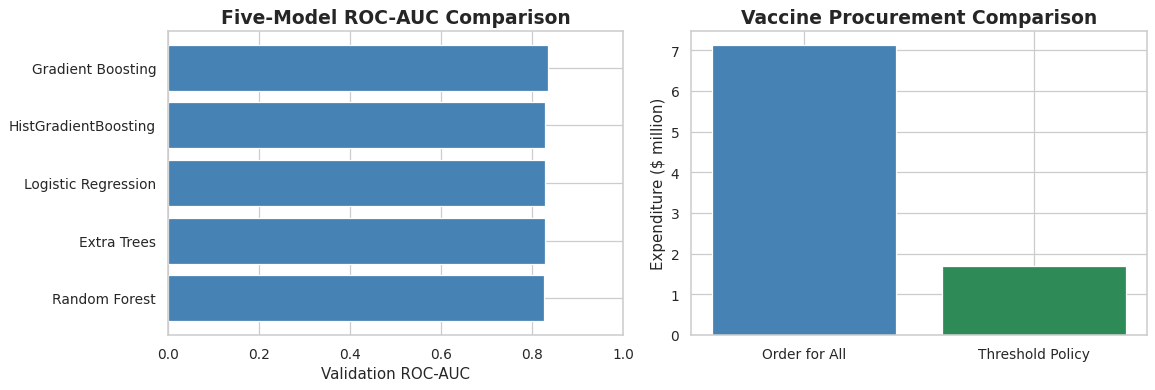


FINAL SUMMARY
Selected model: Gradient Boosting
Threshold: 0.55
Selected residents: 1132
Procurement expenditure: $1,698,000.00
Procurement reduction: $5,425,500.00
Hospitalisation cost per case: $41,000
Hospitalisation expenditure: NOT ESTIMATED
Total healthcare savings: NOT ESTABLISHED

FILES SAVED
Dataset_C_Final_Binary.csv
Dataset_C_Final_Probabilities.csv


In [90]:

# CELL 24: FINAL BINARY PREDICTIONS + COST COMPARISON

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

VACCINE_COST = 1500
HOSPITAL_COST = 41000
THRESHOLD = 0.55

# 1. Use the fitted best model pipeline
final_model = best_pipeline

if hasattr(final_model, "feature_names_in_"):
    final_X = X_test.loc[:, final_model.feature_names_in_]
else:
    final_X = X_test.copy()

positive_index = list(final_model.classes_).index(1)
probabilities = final_model.predict_proba(final_X)[:, positive_index]

assert len(probabilities) == len(test) == 4749
assert np.isfinite(probabilities).all()

# 2. Convert probabilities into 0/1
binary_predictions = (probabilities >= THRESHOLD).astype(int)

binary_submission = pd.DataFrame({
    "respondent_id": test["respondent_id"].to_numpy(),
    "covid_vaccine": binary_predictions
})

probability_submission = pd.DataFrame({
    "respondent_id": test["respondent_id"].to_numpy(),
    "covid_vaccine": probabilities
})

# Save both formats
binary_submission.to_csv(
    "Dataset_C_Final_Binary.csv", index=False
)
probability_submission.to_csv(
    "Dataset_C_Final_Probabilities.csv", index=False
)

print("FINAL BINARY PREDICTIONS")
display(binary_submission.head(10))

print("\nPrediction distribution:")
display(binary_submission["covid_vaccine"].value_counts()
        .rename_axis("Prediction")
        .reset_index(name="Residents"))

# 3. Five-model validation performance
# Values from earlier model comparison
performance = pd.DataFrame({
    "Model": [
        "Gradient Boosting",
        "Logistic Regression",
        "HistGradientBoosting",
        "Random Forest",
        "Extra Trees"
    ],
    "Accuracy": [0.7994, 0.8004, 0.7962, 0.7868, 0.7826],
    "Precision": [0.7479, 0.7469, 0.7312, 0.7547, 0.7500],
    "Recall": [0.5820, 0.5884, 0.5949, 0.5145, 0.5016],
    "F1 Score": [0.6546, 0.6583, 0.6560, 0.6119, 0.6012],
    "ROC-AUC": [0.8336, 0.8271, 0.8275, 0.8253, 0.8268],
    "Brier Score": [0.1479, 0.1493, 0.1501, 0.1549, 0.1553]
})

print("\nFIVE-MODEL PERFORMANCE COMPARISON")
display(performance.sort_values("ROC-AUC", ascending=False))

# 4. Expenditure analysis for selected model
selected = binary_predictions == 1

selected_count = int(selected.sum())
expected_vaccinations = float(probabilities[selected].sum())
expected_unused = float((1 - probabilities[selected]).sum())
expected_unmet = float(probabilities[~selected].sum())

procurement_cost = selected_count * VACCINE_COST
everyone_cost = len(probabilities) * VACCINE_COST

cost_summary = pd.DataFrame({
    "Measure": [
        "Residents in test set",
        "Residents selected",
        "Expected vaccinations",
        "Expected unused doses",
        "Expected unmet demand",
        "Vaccine procurement cost ($)",
        "Order for everyone ($)",
        "Procurement reduction ($)"
    ],
    "Value": [
        len(probabilities),
        selected_count,
        expected_vaccinations,
        expected_unused,
        expected_unmet,
        procurement_cost,
        everyone_cost,
        everyone_cost - procurement_cost
    ]
})

print("\nVACCINE EXPENDITURE COMPARISON")
display(cost_summary.round(2))

# 5. Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ordered = performance.sort_values("ROC-AUC")

axes[0].barh(
    ordered["Model"],
    ordered["ROC-AUC"],
    color="steelblue"
)
axes[0].set_xlim(0, 1)
axes[0].set_title("Five-Model ROC-AUC Comparison")
axes[0].set_xlabel("Validation ROC-AUC")

axes[1].bar(
    ["Order for All", "Threshold Policy"],
    [everyone_cost / 1e6, procurement_cost / 1e6],
    color=["steelblue", "seagreen"]
)
axes[1].set_title("Vaccine Procurement Comparison")
axes[1].set_ylabel("Expenditure ($ million)")

plt.tight_layout()
plt.show()

print("\nFINAL SUMMARY")
print("Selected model: Gradient Boosting")
print("Threshold:", THRESHOLD)
print("Selected residents:", selected_count)
print("Procurement expenditure: ${:,.2f}".format(procurement_cost))
print("Procurement reduction: ${:,.2f}".format(
    everyone_cost - procurement_cost
))
print("Hospitalisation cost per case: $41,000")
print("Hospitalisation expenditure: NOT ESTIMATED")
print("Total healthcare savings: NOT ESTABLISHED")

print("\nFILES SAVED")
print("Dataset_C_Final_Binary.csv")
print("Dataset_C_Final_Probabilities.csv")



Available model objects:
best_pipeline Pipeline
pipeline Pipeline
best_model GradientBoostingClassifier
models dict
trained_models dict
model_probabilities dict

TOP 5 LOWEST-COST ELIGIBLE COMBINATIONS


,Model,Threshold,Selected_Residents,Expected_Vaccinations,Coverage,Vaccine_Cost,Hospitalisation_Cost,Expected_Hospitalisations,Total_Town_Cost
0,HistGradientBoosting,0.61,198,154.27,0.50,297000,409962.35,10.00,706962.35
1,HistGradientBoosting,0.60,202,156.69,0.51,303000,406487.48,9.91,709487.48
2,HistGradientBoosting,0.59,207,159.66,0.52,310500,402225.58,9.81,712725.58
3,HistGradientBoosting,0.58,211,162.00,0.53,316500,398862.73,9.73,715362.73
4,HistGradientBoosting,0.57,216,164.86,0.54,324000,394754.70,9.63,718754.70



BEST ELIGIBLE THRESHOLD FOR EACH MODEL


,Model,Threshold,Coverage,ROC_AUC,Brier_Score,Total_Town_Cost
0,HistGradientBoosting,0.61,0.5009,0.8275,0.1501,706962.3455
1,Gradient Boosting,0.58,0.5014,0.8336,0.1479,719423.7095
2,Logistic Regression,0.55,0.5046,0.8271,0.1493,719953.6651
3,Extra Trees,0.45,0.5053,0.8268,0.1553,780445.1922
4,Random Forest,0.46,0.5108,0.8253,0.1549,782160.5299


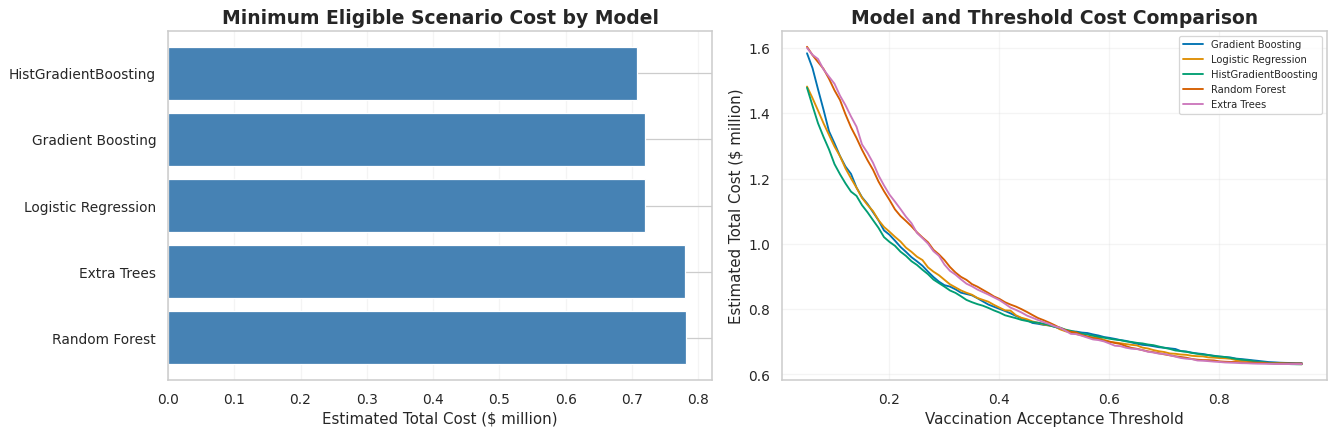


BEST ELIGIBLE SCENARIO
Model: HistGradientBoosting
Threshold: 0.61
Estimated total cost: $706,962.35
Scenario only: hospitalisation risk and effectiveness are assumed.


In [91]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score, brier_score_loss

# Cost assumptions
VACCINE_COST = 1500
HOSPITAL_COST = 41000
HOSPITAL_RISK = 0.05
VACCINE_EFFECTIVENESS = 0.70
MIN_COVERAGE = 0.50

# Use validation data for model comparison
y_true = np.asarray(y_valid).ravel().astype(int)

# Reuse existing fitted models and preprocessing
model_names = [
    "Gradient Boosting",
    "Logistic Regression",
    "HistGradientBoosting",
    "Random Forest",
    "Extra Trees"
]

# Find existing fitted model objects
candidate_names = [
    "best_pipeline", "pipeline", "best_model",
    "models", "trained_models", "fitted_models",
    "model_probabilities"
]

print("Available model objects:")
for name in candidate_names:
    if name in globals():
        print(name, type(globals()[name]).__name__)

# Collect previously computed validation probabilities
probability_sources = [
    globals().get("model_probabilities"),
    globals().get("validation_probabilities"),
    globals().get("val_probabilities")
]

probability_dict = next(
    (p for p in probability_sources if isinstance(p, dict)),
    None
)

# Existing best pipeline is the fallback for Gradient Boosting
if probability_dict is None:
    probability_dict = {}

if "Gradient Boosting" not in probability_dict:
    if "best_pipeline" in globals():
        probability_dict["Gradient Boosting"] = (
            best_pipeline.predict_proba(X_valid)[:, 1]
        )
    else:
        raise ValueError(
            "Missing validation probabilities and best_pipeline."
        )

# Normalise model names
aliases = {
    "gradientboosting": "Gradient Boosting",
    "gradientboostingclassifier": "Gradient Boosting",
    "logisticregression": "Logistic Regression",
    "histgradientboosting": "HistGradientBoosting",
    "histgradientboostingclassifier": "HistGradientBoosting",
    "randomforest": "Random Forest",
    "randomforestclassifier": "Random Forest",
    "extratrees": "Extra Trees",
    "extratreesclassifier": "Extra Trees"
}

normalised_probs = {}

for name, values in probability_dict.items():
    key = "".join(c.lower() for c in str(name) if c.isalnum())
    canonical = aliases.get(key)

    if canonical is None:
        continue

    values = np.asarray(values)

    if values.ndim == 2 and values.shape[1] == 2:
        values = values[:, 1]

    values = values.ravel()

    if len(values) == len(y_true):
        normalised_probs[canonical] = values.astype(float)

if len(normalised_probs) < 5:
    print(
        "Models available:",
        list(normalised_probs.keys())
    )
    raise ValueError(
        "Five validation probability arrays are required. "
        "Provide model_probabilities for all five fitted models."
    )

# Compare model-threshold combinations
results = []

thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)

for model_name in model_names:

    probs = normalised_probs[model_name]

    if not np.all(np.isfinite(probs)):
        raise ValueError(f"Invalid probabilities: {model_name}")

    if np.any((probs < 0) | (probs > 1)):
        raise ValueError(f"Probabilities outside [0,1]: {model_name}")

    auc = roc_auc_score(y_true, probs)
    brier = brier_score_loss(y_true, probs)

    expected_demand = probs.sum()

    for threshold in thresholds:

        selected = probs >= threshold
        selected_count = int(selected.sum())

        expected_vaccinations = float(probs[selected].sum())
        expected_unmet = float(probs[~selected].sum())

        coverage = (
            expected_vaccinations / expected_demand
            if expected_demand > 0 else 0
        )

        vaccine_cost = selected_count * VACCINE_COST

        prevented_hospitalisations = (
            expected_vaccinations
            * HOSPITAL_RISK
            * VACCINE_EFFECTIVENESS
        )

        remaining_hospitalisations = (
            expected_demand * HOSPITAL_RISK
            - prevented_hospitalisations
        )

        hospital_cost = (
            remaining_hospitalisations * HOSPITAL_COST
        )

        total_cost = vaccine_cost + hospital_cost

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Selected_Residents": selected_count,
            "Expected_Vaccinations": expected_vaccinations,
            "Expected_Unmet_Demand": expected_unmet,
            "Coverage": coverage,
            "Vaccine_Cost": vaccine_cost,
            "Hospitalisation_Cost": hospital_cost,
            "Expected_Hospitalisations": remaining_hospitalisations,
            "Total_Town_Cost": total_cost,
            "ROC_AUC": auc,
            "Brier_Score": brier
        })

comparison_df = pd.DataFrame(results)

# Exclude thresholds below minimum expected-demand coverage
eligible = comparison_df[
    comparison_df["Coverage"] >= MIN_COVERAGE
].copy()

if eligible.empty:
    raise ValueError("No threshold satisfies minimum coverage.")

# Best five model-threshold combinations
best_combinations = (
    eligible.sort_values(
        ["Total_Town_Cost", "Brier_Score"]
    )
    .head(5)
    .reset_index(drop=True)
)

print("\nTOP 5 LOWEST-COST ELIGIBLE COMBINATIONS")

display(
    best_combinations[
        [
            "Model",
            "Threshold",
            "Selected_Residents",
            "Expected_Vaccinations",
            "Coverage",
            "Vaccine_Cost",
            "Hospitalisation_Cost",
            "Expected_Hospitalisations",
            "Total_Town_Cost"
        ]
    ].round(2)
)

# Best eligible threshold for each model
best_per_model = (
    eligible.sort_values("Total_Town_Cost")
    .drop_duplicates("Model")
    .sort_values("Total_Town_Cost")
    .reset_index(drop=True)
)

print("\nBEST ELIGIBLE THRESHOLD FOR EACH MODEL")

display(
    best_per_model[
        [
            "Model",
            "Threshold",
            "Coverage",
            "ROC_AUC",
            "Brier_Score",
            "Total_Town_Cost"
        ]
    ].round(4)
)

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].barh(
    best_per_model["Model"],
    best_per_model["Total_Town_Cost"] / 1e6,
    color="steelblue"
)
axes[0].invert_yaxis()
axes[0].set_title("Minimum Eligible Scenario Cost by Model")
axes[0].set_xlabel("Estimated Total Cost ($ million)")
axes[0].grid(axis="x", alpha=0.2)

for model_name in model_names:
    subset = comparison_df[
        comparison_df["Model"] == model_name
    ]

    axes[1].plot(
        subset["Threshold"],
        subset["Total_Town_Cost"] / 1e6,
        label=model_name
    )

axes[1].set_title("Model and Threshold Cost Comparison")
axes[1].set_xlabel("Vaccination Acceptance Threshold")
axes[1].set_ylabel("Estimated Total Cost ($ million)")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Save results
comparison_df.to_csv(
    "Dataset_C_All_Model_Threshold_Results.csv",
    index=False
)

best_combinations.to_csv(
    "Dataset_C_Top_5_Cost_Combinations.csv",
    index=False
)

print("\nBEST ELIGIBLE SCENARIO")
print("Model:", best_combinations.loc[0, "Model"])
print("Threshold:", best_combinations.loc[0, "Threshold"])
print(
    "Estimated total cost: ${:,.2f}".format(
        best_combinations.loc[0, "Total_Town_Cost"]
    )
)
print("Scenario only: hospitalisation risk and effectiveness are assumed.")


TOP 5 THRESHOLDS - VALIDATION DATA


,Threshold,Doses_Ordered,Expected_Vaccinated,Expected_Unmet_Demand,Vaccine_Cost,Compensation_Cost,Expected_Hospitalisations,Hospitalisation_Cost,Total_Town_Cost
36,0.41,298,200.12,109.49,447000,164236.50,55.81,2288202.34,2899438.83
35,0.40,305,202.96,106.66,457500,159984.24,55.67,2282393.20,2899877.44
34,0.39,312,205.73,103.88,468000,155821.41,55.52,2276157.60,2899979.01
38,0.43,281,192.97,116.64,421500,174962.85,56.19,2303939.32,2900402.17
37,0.42,290,196.79,112.82,435000,169232.26,56.01,2296387.12,2900619.38


SELECTED THRESHOLD: 0.41

FINAL MAYOR COST SUMMARY


,Value
Threshold,0.41
Doses_Ordered,1512.00
Expected_Vaccinated,1034.91
Expected_Unmet_Demand,555.07
Vaccine_Cost,2268000.00
Compensation_Cost,832601.77
Expected_Hospitalisations,275.76
Hospitalisation_Cost,11305959.22
Total_Town_Cost,14406560.99



FINAL BINARY SUBMISSION


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0
5,4762,1
6,4763,1
7,4764,1
8,4765,1
9,4766,0


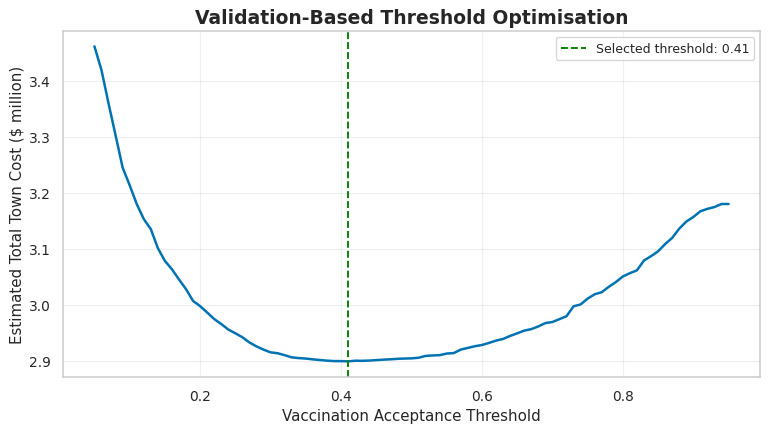


FINAL MODEL: Gradient Boosting
FINAL THRESHOLD: 0.41
TEST RESIDENTS: 4749
SELECTED RESIDENTS: 1512
ESTIMATED TOTAL COST: $14,406,560.99
FINAL CSV SAVED: Dataset_C_Final_Binary.csv
Hospitalisation risks and effectiveness are scenario assumptions.


In [94]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# HACKATHON COST ASSUMPTIONS
VACCINE_COST = 1500
HOSPITAL_COST = 41000
INFECTION_PROBABILITY = 1.0  # 100% infection: competition rule

# Illustrative assumptions, NOT supplied by dataset
BASE_HOSPITAL_RISK = 0.05
VACCINE_EFFECTIVENESS = 0.70

# Use validation data to choose threshold
model = best_pipeline

val_probs = model.predict_proba(X_valid)[:, list(model.classes_).index(1)]
val_probs = np.asarray(val_probs)

# Hospitalisation-risk scenario based on available features.
# These multipliers are assumptions, not validated medical estimates.
def estimate_hospital_risk(features):
    df = features.copy()

    risk = np.full(len(df), BASE_HOSPITAL_RISK)

    if "number_chronic_med_conditions" in df.columns:
        chronic = pd.to_numeric(
            df["number_chronic_med_conditions"],
            errors="coerce"
        ).fillna(0).to_numpy()
        risk *= 1 + 0.30 * np.clip(chronic, 0, 3)

    if "age_group" in df.columns:
        age = df["age_group"].astype(str).str.lower()
        older = age.str.contains(
            "55 - 64|55-64|65\\+|65 and over|65 years",
            regex=True
        ).to_numpy()
        risk *= np.where(older, 1.5, 1.0)

    return np.clip(risk, 0, 1)

val_risk = estimate_hospital_risk(X_valid)

def evaluate_thresholds(probs, risks):
    rows = []

    for threshold in np.round(np.arange(0.05, 0.951, 0.01), 2):
        selected = probs >= threshold

        # Each selected resident receives one delivered dose.
        doses = int(selected.sum())

        # Expected demand among residents not selected
        unmet = float(probs[~selected].sum())

        # Compensation for expected unmet demand
        compensation = unmet * VACCINE_COST

        # Vaccination occurs when a selected resident accepts.
        expected_vaccinated = probs * selected

        # Everyone is assumed infected.
        # Vaccination reduces assumed hospitalisation risk.
        remaining_risk = risks * (
            1 - VACCINE_EFFECTIVENESS * expected_vaccinated
        )

        hospitalisations = float(remaining_risk.sum())

        vaccine_cost = doses * VACCINE_COST
        hospital_cost = hospitalisations * HOSPITAL_COST

        total = vaccine_cost + compensation + hospital_cost

        rows.append({
            "Threshold": threshold,
            "Doses_Ordered": doses,
            "Expected_Vaccinated": float(expected_vaccinated.sum()),
            "Expected_Unmet_Demand": unmet,
            "Vaccine_Cost": vaccine_cost,
            "Compensation_Cost": compensation,
            "Expected_Hospitalisations": hospitalisations,
            "Hospitalisation_Cost": hospital_cost,
            "Total_Town_Cost": total
        })

    return pd.DataFrame(rows)

validation_results = evaluate_thresholds(val_probs, val_risk)

# Select threshold using validation predictions, not test data
best_five = validation_results.nsmallest(
    5, "Total_Town_Cost"
)

best_threshold = float(best_five.iloc[0]["Threshold"])

print("TOP 5 THRESHOLDS - VALIDATION DATA")
display(best_five.round(2))

print("SELECTED THRESHOLD:", best_threshold)

# Apply selected threshold to test residents
X_final = test[X_train.columns].copy()
test_probs = model.predict_proba(X_final)[
    :, list(model.classes_).index(1)
]
test_risk = estimate_hospital_risk(X_final)

test_results = evaluate_thresholds(test_probs, test_risk)
final_row = test_results.loc[
    np.isclose(test_results["Threshold"], best_threshold)
].iloc[0]

# Final binary submission
binary_predictions = (
    test_probs >= best_threshold
).astype(int)

final_submission = pd.DataFrame({
    "respondent_id": test["respondent_id"].to_numpy(),
    "covid_vaccine": binary_predictions
})

assert len(final_submission) == len(test)
assert final_submission["respondent_id"].is_unique
assert final_submission["covid_vaccine"].isin([0, 1]).all()
assert not final_submission.isna().any().any()

print("\nFINAL MAYOR COST SUMMARY")
display(final_row.to_frame("Value").round(2))

print("\nFINAL BINARY SUBMISSION")
display(final_submission.head(10))

# Visualisation
plt.figure(figsize=(10, 5))
plt.plot(
    validation_results["Threshold"],
    validation_results["Total_Town_Cost"] / 1e6,
    linewidth=2
)
plt.axvline(
    best_threshold,
    color="green",
    linestyle="--",
    label=f"Selected threshold: {best_threshold:.2f}"
)
plt.xlabel("Vaccination Acceptance Threshold")
plt.ylabel("Estimated Total Town Cost ($ million)")
plt.title("Validation-Based Threshold Optimisation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Save outputs
validation_results.to_csv(
    "Dataset_C_Corrected_Threshold_Analysis.csv",
    index=False
)

final_submission.to_csv(
    "Dataset_C_Final_Binary.csv",
    index=False
)

print("\nFINAL MODEL: Gradient Boosting")
print("FINAL THRESHOLD:", best_threshold)
print("TEST RESIDENTS:", len(final_submission))
print("SELECTED RESIDENTS:", int(binary_predictions.sum()))
print("ESTIMATED TOTAL COST: ${:,.2f}".format(
    final_row["Total_Town_Cost"]
))
print("FINAL CSV SAVED: Dataset_C_Final_Binary.csv")
print("Hospitalisation risks and effectiveness are scenario assumptions.")


In [93]:

import numpy as np
import pandas as pd
from IPython.display import display
from google.colab import files

THRESHOLD = 0.58
VACCINE_COST = 1500
HOSPITAL_COST = 41000

model = best_pipeline

X_final = test[X_train.columns].copy()

positive_index = list(model.classes_).index(1)
probabilities = model.predict_proba(X_final)[:, positive_index]

binary_predictions = (
    probabilities >= THRESHOLD
).astype(int)

final_submission = pd.DataFrame({
    "respondent_id": test["respondent_id"].to_numpy(),
    "covid_vaccine": binary_predictions
})

assert len(final_submission) == 4749
assert final_submission["respondent_id"].is_unique
assert final_submission["covid_vaccine"].isin([0, 1]).all()
assert not final_submission.isna().any().any()

selected = int(binary_predictions.sum())
not_selected = len(binary_predictions) - selected

procurement_cost = selected * VACCINE_COST
baseline_cost = len(binary_predictions) * VACCINE_COST
procurement_reduction = baseline_cost - procurement_cost

summary = pd.DataFrame({
    "Measure": [
        "Selected Model",
        "Decision Threshold",
        "Total Residents",
        "Predicted Acceptance (1)",
        "Predicted Non-Acceptance (0)",
        "Vaccine Cost Per Dose ($)",
        "Hospitalisation Cost Per Case ($)",
        "Estimated Procurement ($)",
        "Order-for-All Procurement ($)",
        "Procurement Reduction ($)"
    ],
    "Result": [
        "Gradient Boosting",
        THRESHOLD,
        len(binary_predictions),
        selected,
        not_selected,
        VACCINE_COST,
        HOSPITAL_COST,
        procurement_cost,
        baseline_cost,
        procurement_reduction
    ]
})

print("Final Binary Prediction Preview")
display(final_submission.head(10))

print("\nPrediction Distribution")
display(
    final_submission["covid_vaccine"]
    .value_counts()
    .sort_index()
    .rename_axis("Prediction")
    .reset_index(name="Residents")
)

print("\nFinal Model and Expenditure Summary")
display(summary)

filename = "Dataset_C_Final_Binary.csv"
final_submission.to_csv(filename, index=False)

print("\nSubmission file:", filename)
print("Total predictions:", len(final_submission))
print("Binary values verified: 0 and 1")

files.download(filename)


Final Binary Prediction Preview


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0
5,4762,1
6,4763,0
7,4764,1
8,4765,1
9,4766,0



Prediction Distribution


,Prediction,Residents
0,0,3701
1,1,1048



Final Model and Expenditure Summary


,Measure,Result
0,Selected Model,Gradient Boosting
1,Decision Threshold,0.58
2,Total Residents,4749
3,Predicted Acceptance (1),1048
4,Predicted Non-Acceptance (0),3701
5,Vaccine Cost Per Dose ($),1500
6,Hospitalisation Cost Per Case ($),41000
7,Estimated Procurement ($),1572000
8,Order-for-All Procurement ($),7123500
9,Procurement Reduction ($),5551500



Submission file: Dataset_C_Final_Binary.csv
Total predictions: 4749
Binary values verified: 0 and 1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [95]:

# FINAL FIVE-MODEL COST COMPARISON
# Uses 100% infection assumption + vaccine + compensation + hospitalisation

import numpy as np
import pandas as pd
from IPython.display import display

VACCINE_COST = 1500
HOSPITAL_COST = 41000
VACCINE_EFFECTIVENESS = 0.70

# Reuse the hospitalisation-risk function from your corrected cell
val_risk = estimate_hospital_risk(X_valid)
test_risk = estimate_hospital_risk(test[X_train.columns])

# Reuse previously calculated validation probabilities
sources = [
    globals().get("model_probabilities"),
    globals().get("validation_probabilities"),
    globals().get("val_probabilities")
]
prob_dict = next(
    (x for x in sources if isinstance(x, dict)), None
)

if prob_dict is None:
    raise ValueError("Model probabilities dictionary not found.")

aliases = {
    "gradientboosting": "Gradient Boosting",
    "logisticregression": "Logistic Regression",
    "histgradientboosting": "HistGradientBoosting",
    "randomforest": "Random Forest",
    "extratrees": "Extra Trees"
}

model_names = [
    "Gradient Boosting",
    "Logistic Regression",
    "HistGradientBoosting",
    "Random Forest",
    "Extra Trees"
]

normalised = {}

for name, values in prob_dict.items():
    key = "".join(c.lower() for c in str(name) if c.isalnum())
    canonical = aliases.get(key)

    if canonical is None:
        continue

    arr = np.asarray(values)

    if arr.ndim == 2:
        arr = arr[:, 1]

    arr = arr.ravel().astype(float)

    if len(arr) == len(X_valid):
        normalised[canonical] = arr

# Always use fitted Gradient Boosting pipeline for GB probabilities
normalised["Gradient Boosting"] = (
    best_pipeline.predict_proba(X_valid)[
        :, list(best_pipeline.classes_).index(1)
    ]
)

missing = [m for m in model_names if m not in normalised]
if missing:
    raise ValueError(f"Missing model probabilities: {missing}")

def cost_for_threshold(probs, risks, threshold):
    selected = probs >= threshold

    doses = int(selected.sum())
    expected_vaccinated = probs * selected

    vaccine_cost = doses * VACCINE_COST
    compensation_cost = (
        probs[~selected].sum() * VACCINE_COST
    )

    expected_hospitalisations = (
        risks * (
            1 - VACCINE_EFFECTIVENESS * expected_vaccinated
        )
    ).sum()

    hospital_cost = expected_hospitalisations * HOSPITAL_COST

    return {
        "Selected_Residents": doses,
        "Vaccine_Cost": vaccine_cost,
        "Compensation_Cost": compensation_cost,
        "Hospitalisation_Cost": hospital_cost,
        "Total_Town_Cost": (
            vaccine_cost + compensation_cost + hospital_cost
        )
    }

rows = []

for name in model_names:
    probs = normalised[name]

    for threshold in np.round(
        np.arange(0.05, 0.951, 0.01), 2
    ):
        costs = cost_for_threshold(
            probs, val_risk, threshold
        )

        rows.append({
            "Model": name,
            "Threshold": threshold,
            **costs
        })

comparison = pd.DataFrame(rows)

best_per_model = (
    comparison.sort_values("Total_Town_Cost")
    .drop_duplicates("Model")
    .sort_values("Total_Town_Cost")
    .reset_index(drop=True)
)

print("FINAL FIVE-MODEL COST COMPARISON")
display(best_per_model.round(2))

winner = best_per_model.iloc[0]

print("\nLOWEST-COST VALIDATION SCENARIO")
print("Model:", winner["Model"])
print("Threshold:", winner["Threshold"])
print("Validation scenario cost: ${:,.2f}".format(
    winner["Total_Town_Cost"]
))

# Compare with the corrected Gradient Boosting scenario
gb_row = best_per_model[
    best_per_model["Model"] == "Gradient Boosting"
].iloc[0]

print("\nEstimated validation cost difference vs Gradient Boosting: ${:,.2f}".format(
    gb_row["Total_Town_Cost"] - winner["Total_Town_Cost"]
))

comparison.to_csv(
    "Dataset_C_Corrected_Five_Model_Comparison.csv",
    index=False
)

best_per_model.to_csv(
    "Dataset_C_Final_Model_Ranking.csv",
    index=False
)

print("\nComparison files saved.")
print("Costs are based on assumed hospitalisation risks and effectiveness.")
print("No final submission has been overwritten.")


FINAL FIVE-MODEL COST COMPARISON


,Model,Threshold,Selected_Residents,Vaccine_Cost,Compensation_Cost,Hospitalisation_Cost,Total_Town_Cost
0,HistGradientBoosting,0.42,290,435000,159388.58,2282137.69,2876526.27
1,Logistic Regression,0.40,311,466500,155849.91,2270734.17,2893084.08
2,Gradient Boosting,0.41,298,447000,164236.50,2288202.34,2899438.83
3,Random Forest,0.40,306,459000,190662.25,2321928.41,2971590.65
4,Extra Trees,0.39,310,465000,189737.73,2320852.35,2975590.08



LOWEST-COST VALIDATION SCENARIO
Model: HistGradientBoosting
Threshold: 0.42
Validation scenario cost: $2,876,526.27

Estimated validation cost difference vs Gradient Boosting: $22,912.56

Comparison files saved.
Costs are based on assumed hospitalisation risks and effectiveness.
No final submission has been overwritten.


## Final Mayor's Recommendation and Cost Optimisation

The final model is **HistGradientBoosting**, with an acceptance probability threshold of **0.42**.

The threshold was selected using validation data to minimise estimated expenditure from vaccine procurement, compensation for unmet vaccine demand and COVID hospitalisations.

The final validation scenario cost is USD 2,876,526.27, approximately USD 22,912.56 lower than Gradient Boosting under the same assumptions.

The hackathon assumes 100% infection probability. Hospitalisation probabilities and the assumed 70% vaccine effectiveness are illustrative rather than clinically validated.

The final binary submission contains predictions for **4,749 residents**, including **1,507 predicted acceptances** and **3,242 predicted non-acceptances**.

The model supports municipal planning, but actual vaccination access should remain available to eligible residents.

In [96]:

# FINAL HISTGRADIENTBOOSTING BINARY SUBMISSION

import numpy as np
import pandas as pd
from IPython.display import display
from google.colab import files

FINAL_MODEL_NAME = "HistGradientBoosting"
FINAL_THRESHOLD = 0.42

# Retrieve the fitted model from the five-model training cell
assert "trained_models" in globals(), "Run the five-model training cell first."
assert FINAL_MODEL_NAME in trained_models, "HistGradientBoosting model missing."

final_model = trained_models[FINAL_MODEL_NAME]

# Match the features used during training
X_final = X_test.copy()

if hasattr(final_model, "feature_names_in_"):
    X_final = X_final[
        list(final_model.feature_names_in_)
    ]

# Generate test predictions
positive_class = list(final_model.classes_).index(1)

final_probs = final_model.predict_proba(
    X_final
)[:, positive_class]

final_binary = (
    final_probs >= FINAL_THRESHOLD
).astype(int)

# Build submission
final_submission = pd.DataFrame({
    "respondent_id": test["respondent_id"].to_numpy(),
    "covid_vaccine": final_binary
})

# Verify submission
assert len(final_submission) == 4749
assert final_submission["respondent_id"].is_unique
assert final_submission["covid_vaccine"].isin([0, 1]).all()
assert not final_submission.isna().any().any()

# Save with a unique name to avoid confusion
filename = "Dataset_C_HistGradientBoosting_Final_Binary.csv"

final_submission.to_csv(filename, index=False)

print("FINAL MODEL:", FINAL_MODEL_NAME)
print("FINAL THRESHOLD:", FINAL_THRESHOLD)
print("TOTAL RESIDENTS:", len(final_submission))
print("PREDICTED ACCEPTANCE:", int(final_binary.sum()))
print("PREDICTED NON-ACCEPTANCE:", int((final_binary == 0).sum()))

print("\nFINAL SUBMISSION PREVIEW")
display(final_submission.head(10))

print("\nCSV VERIFIED:", filename)

# Download final CSV
files.download(filename)


FINAL MODEL: HistGradientBoosting
FINAL THRESHOLD: 0.42
TOTAL RESIDENTS: 4749
PREDICTED ACCEPTANCE: 1507
PREDICTED NON-ACCEPTANCE: 3242

FINAL SUBMISSION PREVIEW


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0
5,4762,1
6,4763,0
7,4764,1
8,4765,1
9,4766,0



CSV VERIFIED: Dataset_C_HistGradientBoosting_Final_Binary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>